<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-028-trajectories.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 028 <br>
<hr/>

# Lab 028 — Physical parameters from trajectories

A physicist who watches a mass oscillate on a spring summarises the motion by a few numbers: how fast it oscillates, how quickly the oscillation dies out, where it started. In this notebook a neural network is given only the recorded positions $x(t_1),\dots,x(t_{100})$ of many such oscillators, each with its own spring, its own friction and its own initial condition, all shaken by a small random force. The network is a $\beta$-variational autoencoder ($\beta$-VAE, Lab 026): it compresses each trajectory into a few latent coordinates and is pushed by the weight $\beta$ to use them sparingly and independently. Because we generated the data ourselves, we know the true physical parameters of every trajectory, and we can check which of them, if any, the latent coordinates have learned. This is an interpretability experiment with a known answer.

Section 1 develops the physics: the damped oscillator driven by Gaussian white noise, its underdamped and overdamped regimes, and its numerical integration with the Euler–Maruyama scheme, checked against the exact mean and the exact stationary variance. Section 2 generates the data set. Section 3 builds and trains the $\beta$-VAE for several values of $\beta$ and several random seeds. Section 4 follows the interpretability protocol of the lecture: active coordinates, correlations with the true parameters, the mutual information gap, latent traversals, and a physical explanation of what the network can and cannot separate, based on how sensitive a trajectory is to each parameter. Section 5 describes the question-and-answer network of Iten *et al.*, which found the spring constant and the damping factor of a damped pendulum, reimplements it, and compares it with the $\beta$-VAE on the same data, with and without noise and random initial conditions. Section 6 repeats the experiment for two coupled masses, where the trajectories depend on the springs only through two normal-mode frequencies.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`; all networks are small and the notebook runs on a CPU.
> 2. `jax`, `flax`, `optax`, `sympy`, `scipy` and `matplotlib` are pre-installed in Colab. No data are downloaded: every trajectory is simulated here.
> 3. Trained parameters are stored; if they are present they are loaded instead of training again.
> 4. Run the cells *in order*: later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # run JAX on the CPU (set before importing jax)
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import json, time, pickle
from functools import partial
import numpy as np
import sympy as sp
import scipy.linalg
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch, Circle
from matplotlib.colors import Normalize

import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx

mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0})
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})
# style of the figures made for the slides: drawn at their physical size on a 16:9 slide (text width 5.5 in)
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 12, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5,
            "figure.constrained_layout.use": True}     # the saved figure has exactly its figsize

UJBlue, UJNavy, DSOrange, UJGray, UJSky = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#3E8FD0"

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)
CKPT = "checkpoints"
os.makedirs(OUT, exist_ok=True); os.makedirs(CKPT, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=200)

nums = {}                                    # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6 | devices: [CpuDevice(id=0)]


<hr/>
## 1. The noisy damped oscillator

### 1.1 Equation of motion

A particle of mass $m$ is attached to a spring of spring constant $k$ and moves in a viscous fluid. The spring pulls it back with the force $-kx$, the fluid slows it down with the friction force $-m\gamma\dot x$, and the molecules of the fluid hit it at random, which we describe by a random force. Dividing Newton's equation by $m$ gives the Langevin equation of the damped oscillator,
$$\ddot x=-\omega^2x-\gamma\dot x+\sqrt{2D}\,\xi(t),\qquad \omega=\sqrt{k/m}.$$
Here $\omega$ is the angular frequency the oscillator would have without friction, $\gamma$ is the friction rate (the inverse of the time in which friction alone would stop a free particle), and $\xi(t)$ is Gaussian white noise: at every time $t$ a Gaussian random number with
$$\langle\xi(t)\rangle=0,\qquad \langle\xi(t)\,\xi(t')\rangle=\delta(t-t'),$$
so that values at different times are independent, however close the times are. The brackets $\langle\cdot\rangle$ denote the average over many realisations of the noise. The constant $D$, the noise strength, sets the size of the random force; since $\xi$ has the unit $\mathrm{s}^{-1/2}$, $D$ has the unit $\mathrm{m}^2/\mathrm{s}^3$. We will show in Section 1.3 that in the stationary state $\langle\dot x^2\rangle=D/\gamma$. If the random force comes from a fluid at temperature $T$, equipartition requires $\langle\dot x^2\rangle=k_BT/m$, and therefore $D=\gamma k_BT/m$: friction and noise have the same origin and are tied together (Einstein relation). Throughout the notebook $m=1$.

Without noise the equation is linear, and the ansatz $x=e^{\lambda t}$ gives the characteristic equation $\lambda^2+\gamma\lambda+\omega^2=0$ with roots
$$\lambda_\pm=-\frac\gamma2\pm\sqrt{\frac{\gamma^2}{4}-\omega^2}.$$
Two regimes follow. If $\gamma<2\omega$ (**underdamped**), the roots are complex and the particle oscillates at the damped frequency $\omega_d=\sqrt{\omega^2-\gamma^2/4}$ inside an envelope $e^{-\gamma t/2}$:
$$x(t)=e^{-\gamma t/2}\Big[x_0\cos\omega_dt+\frac{v_0+\gamma x_0/2}{\omega_d}\sin\omega_dt\Big],$$
with $x_0=x(0)$ and $v_0=\dot x(0)$. The frequency $\omega$ sets how often the particle crosses zero, $\gamma$ sets how fast the oscillation dies out. If $\gamma>2\omega$ (**overdamped**), both roots are real and negative: the particle creeps back to $x=0$ without oscillating, with the slower of the two rates $|\lambda_+|$ dominating at long times. At $\gamma=2\omega$ (critical damping) the return is fastest. The cell below checks the roots and the underdamped solution with SymPy, and expands the slow rate for strong friction.

In [2]:
t, w, g = sp.symbols("t omega gamma", positive=True)
lam, x0s, v0s = sp.symbols("lambda x_0 v_0")

# characteristic equation of  x'' + gamma x' + omega^2 x = 0  for x = exp(lambda t)
roots = sp.solve(sp.Eq(lam**2 + g * lam + w**2, 0), lam)
print("lambda =", roots)

# underdamped solution with x(0) = x0, x'(0) = v0
wd = sp.sqrt(w**2 - g**2 / 4)
x_under = sp.exp(-g * t / 2) * (x0s * sp.cos(wd * t) + (v0s + g * x0s / 2) / wd * sp.sin(wd * t))
print("residual of the equation of motion:", sp.simplify(sp.diff(x_under, t, 2) + g * sp.diff(x_under, t) + w**2 * x_under))
print("x(0) =", x_under.subs(t, 0), "   x'(0) =", sp.simplify(sp.diff(x_under, t).subs(t, 0)))

# overdamped: the slower of the two decay rates, expanded for omega << gamma
rate_slow = g / 2 - sp.sqrt(g**2 / 4 - w**2)
print("slow decay rate for omega << gamma:", sp.series(rate_slow, w, 0, 5).removeO())

lambda = [-gamma/2 - sqrt(gamma**2 - 4*omega**2)/2, -gamma/2 + sqrt(gamma**2 - 4*omega**2)/2]


residual of the equation of motion: 0
x(0) = x_0    x'(0) = v_0
slow decay rate for omega << gamma: omega**2/gamma + omega**4/gamma**3


The residual vanishes and the initial conditions are reproduced. For strong friction the slow rate is $\omega^2/\gamma$: deep in the overdamped regime a trajectory depends on $\omega$ and $\gamma$ essentially only through the combination $\omega^2/\gamma$, a fact we will test on the latent coordinates in Section 4.5.

For any regime the noise-free motion can be written compactly. With the state $\mathbf s=(x,v)$ the equation reads $\dot{\mathbf s}=A\mathbf s$ with the drift matrix
$$A=\begin{pmatrix}0&1\\-\omega^2&-\gamma\end{pmatrix},\qquad \mathbf s(t)=e^{At}\,\mathbf s(0).$$
The function `mean_trajectory` evaluates this matrix exponential. We will see in Section 1.3 that it is also the **mean** of the noisy trajectories, so it serves as the exact reference throughout the notebook.

In [3]:
def drift_matrix(omega, gamma):
    """A in d(x, v)/dt = A (x, v) for the oscillator without noise."""
    return jnp.array([[0.0, 1.0], [-omega**2, -gamma]])

def mean_trajectory(omega, gamma, x0, v0, t):
    """<x(t)> = first component of expm(A t) (x0, v0) on the times t (any regime)."""
    A = drift_matrix(omega, gamma)
    s0 = jnp.stack([x0, v0])
    return jax.vmap(lambda tt: (jax.scipy.linalg.expm(A * tt) @ s0)[0])(t)

# many trajectories at once: parameters (N,), times (T,) -> (N, T)
mean_trajectories = jax.jit(jax.vmap(mean_trajectory, in_axes=(0, 0, 0, 0, None)))

# the matrix exponential agrees with the closed-form underdamped solution of SymPy
f_under = sp.lambdify((t, w, g, x0s, v0s), x_under, "numpy")
tt = np.linspace(0, 6, 7)
print("max |expm - closed form| =", np.abs(np.asarray(mean_trajectory(1.5, 0.4, 1.0, 0.3, jnp.asarray(tt)))
                                          - f_under(tt, 1.5, 0.4, 1.0, 0.3)).max())

max |expm - closed form| = 4.785956852493278e-07


The figure shows the system and the role of the two parameters. In the middle panel only $\omega$ changes: the zero crossings move closer together as $\omega$ grows, while the envelope stays the same. In the right panel only $\gamma$ changes: from a slowly decaying oscillation ($\gamma=0.2$) through a strongly damped one ($\gamma=1$) to an overdamped creep without any oscillation ($\gamma=5>2\omega=3$).

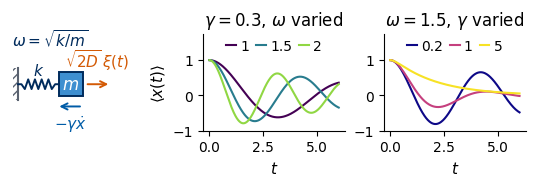

In [4]:
def draw_spring(ax, x_start, x_end, y, n_coils=6, height=0.12, **kw):
    """Zig-zag spring between (x_start, y) and (x_end, y)."""
    xs = np.linspace(x_start, x_end, 2 * n_coils + 3)
    ys = np.full_like(xs, y)
    ys[1:-1:2] += height; ys[2:-1:2] -= height
    ys[1], ys[-2] = y, y                               # straight ends
    ax.plot(xs, ys, color=UJNavy, lw=1.4, **kw)

def draw_wall(ax, x, y0, y1, side="left"):
    """Hatched wall at x between heights y0 and y1."""
    w = -0.12 if side == "left" else 0.12
    ax.add_patch(Rectangle((x, y0), w, y1 - y0, facecolor="none", edgecolor=UJGray, hatch="////", lw=0))
    ax.plot([x, x], [y0, y1], color=UJGray, lw=1.5)

def draw_oscillator_sketch(ax):
    """Mass on a spring with friction and a random force."""
    draw_wall(ax, 0.0, -0.4, 0.4)
    draw_spring(ax, 0.0, 1.0, 0.0, n_coils=5)
    ax.add_patch(Rectangle((1.0, -0.3), 0.6, 0.6, facecolor=UJSky, edgecolor=UJNavy, lw=1.4))
    ax.text(1.3, 0.0, "$m$", ha="center", va="center", fontsize=12, color="white")
    ax.text(0.5, 0.22, "$k$", ha="center", fontsize=11, color=UJNavy)
    ax.annotate("", xy=(2.3, 0.0), xytext=(1.65, 0.0), arrowprops=dict(arrowstyle="->", color=DSOrange, lw=1.4))
    ax.text(1.95, 0.42, r"$\sqrt{2D}\,\xi(t)$", ha="center", fontsize=11, color=DSOrange)
    ax.annotate("", xy=(0.95, -0.55), xytext=(1.6, -0.55), arrowprops=dict(arrowstyle="->", color=UJBlue, lw=1.4))
    ax.text(1.3, -0.72, r"$-\gamma\dot x$", ha="center", va="top", fontsize=11, color=UJBlue)
    ax.text(0.8, 0.95, r"$\omega=\sqrt{k/m}$", ha="center", fontsize=11, color=UJNavy)
    ax.set_xlim(-0.2, 2.4); ax.set_ylim(-1.15, 1.25); ax.set_aspect("equal"); ax.axis("off")

t_demo = jnp.linspace(0, 6, 300)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.75), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
    draw_oscillator_sketch(axs[0])
    cm_w, cm_g = plt.get_cmap("viridis"), plt.get_cmap("plasma")
    for om in [1.0, 1.5, 2.0]:
        axs[1].plot(t_demo, mean_trajectory(om, 0.3, 1.0, 0.0, t_demo), color=cm_w((om - 1) / 1.2), label=f"{om:g}")
    for ga in [0.2, 1.0, 5.0]:
        axs[2].plot(t_demo, mean_trajectory(1.5, ga, 1.0, 0.0, t_demo), color=cm_g(np.log(ga / 0.2) / np.log(30)), label=f"{ga:g}")
    axs[1].set_title(r"$\gamma=0.3$, $\omega$ varied"); axs[2].set_title(r"$\omega=1.5$, $\gamma$ varied")
    for a in axs[1:]:
        a.legend(loc="upper center", ncol=3, handlelength=0.7, columnspacing=0.5, handletextpad=0.3, borderaxespad=0.0)
        a.set_xlabel("$t$"); a.set_ylim(-1.0, 1.75); a.set_yticks([-1, 0, 1])
    axs[1].set_ylabel(r"$\langle x(t)\rangle$")
    save(fig, "gen_traj_oscillator.png"); plt.show()

### 1.2 Euler–Maruyama integration

To simulate the noisy equation we write it as two first-order equations and integrate them over one small time step $\Delta t$. Integrating $\xi$ over an interval gives the increment of the Wiener process (Brownian motion), $\Delta W=\int_t^{t+\Delta t}\xi(s)\,ds$. It is Gaussian with mean zero and variance
$$\begin{aligned}
\langle\Delta W^2\rangle&=\int_t^{t+\Delta t}\!\!\int_t^{t+\Delta t}\langle\xi(s)\xi(s')\rangle\,ds\,ds'\\
&=\int_t^{t+\Delta t}ds=\Delta t,
\end{aligned}$$
so $\Delta W=\sqrt{\Delta t}\,\eta$ with $\eta\sim\mathcal N(0,1)$, and increments over different steps are independent. Approximating the smooth terms by their values at the beginning of the step,
$$\begin{aligned}
x_{n+1}&=x_n+v_n\,\Delta t,\\
v_{n+1}&=v_n+\big(-\omega^2x_n-\gamma v_n\big)\Delta t+\sqrt{2D\,\Delta t}\;\eta_n,
\end{aligned}$$
with independent $\eta_n\sim\mathcal N(0,1)$.
This is the Euler–Maruyama scheme [Kloeden and Platen 1992; Higham 2001]. Its one feature that differs from the ordinary Euler method is the factor $\sqrt{\Delta t}$ in the noise term: the random kicks of one step add up like a random walk, so their typical size grows as the square root of the time. Averages computed with the scheme converge to the exact ones with an error proportional to $\Delta t$ (weak order one). We use $\Delta t=0.01$, small compared with the shortest time scale of our data, $1/\omega\ge0.5$ and $1/\gamma\ge1/6$.

The function below integrates many oscillators at once: one `lax.scan` over the steps between two recorded points, nested inside a `lax.scan` over the recorded points.

In [5]:
DT = 0.01            # Euler-Maruyama time step
D_NOISE = 0.002      # noise strength D of all data sets

def simulate(omega, gamma, x0, v0, key, D=D_NOISE, dt=DT, n_sub=6, n_rec=100):
    """Euler-Maruyama for N independent oscillators; omega, gamma, x0, v0 have shape (N,).
    Returns positions and velocities (N, n_rec) at the times 0, n_sub*dt, 2*n_sub*dt, ..."""
    def em_step(state, k):
        x, v = state
        eta = jax.random.normal(k, x.shape)                       # eta ~ N(0, 1), independent in every step
        return (x + v * dt, v + (-omega**2 * x - gamma * v) * dt + jnp.sqrt(2 * D * dt) * eta), None
    def record(state, k):                                         # n_sub steps between two recorded points
        state, _ = jax.lax.scan(em_step, state, jax.random.split(k, n_sub))
        return state, state
    _, (xs, vs) = jax.lax.scan(record, (x0, v0), jax.random.split(key, n_rec - 1))
    return jnp.concatenate([x0[None], xs]).T, jnp.concatenate([v0[None], vs]).T

simulate = jax.jit(simulate, static_argnames=("n_sub", "n_rec"))

### 1.3 Exact mean and stationary variance

Averaging the update over the noise removes the term with $\eta_n$, because $\langle\eta_n\rangle=0$ and the update is linear. The averages $\langle x_n\rangle,\langle v_n\rangle$ therefore obey exactly the noise-free recursion, and for $\Delta t\to0$ the mean trajectory is the noise-free solution $e^{At}\mathbf s(0)$ of Section 1.1.

For the fluctuations we write the update as $\mathbf s_{n+1}=M\mathbf s_n+\mathbf b\,\eta_n$ with $M=I+A\Delta t$ and $\mathbf b=(0,\sqrt{2D\Delta t})$. Since $\eta_n$ is independent of $\mathbf s_n$, the covariance matrix $\Sigma=\langle\mathbf s\mathbf s^{\mathsf T}\rangle-\langle\mathbf s\rangle\langle\mathbf s\rangle^{\mathsf T}$ obeys
$$\begin{aligned}
\Sigma_{n+1}&=M\Sigma_nM^{\mathsf T}+\mathbf b\mathbf b^{\mathsf T},\\
\frac{\Sigma_{n+1}-\Sigma_n}{\Delta t}&=A\Sigma_n+\Sigma_nA^{\mathsf T}+Q+O(\Delta t),\qquad Q=\begin{pmatrix}0&0\\0&2D\end{pmatrix}.
\end{aligned}$$
In the stationary state the left-hand side vanishes, and $\Sigma$ solves the Lyapunov equation $A\Sigma+\Sigma A^{\mathsf T}+Q=0$, three linear equations for $\langle x^2\rangle,\langle xv\rangle,\langle v^2\rangle$. SymPy solves them:

In [6]:
Sxx, Sxv, Svv, D_s = sp.symbols("S_xx S_xv S_vv D", real=True)
A_s = sp.Matrix([[0, 1], [-w**2, -g]])
Sig = sp.Matrix([[Sxx, Sxv], [Sxv, Svv]])
Q_s = sp.diag(0, 2 * D_s)
sol = sp.solve(list(A_s * Sig + Sig * A_s.T + Q_s), [Sxx, Sxv, Svv], dict=True)[0]
print("stationary <x^2> =", sol[Sxx], "   <x v> =", sol[Sxv], "   <v^2> =", sol[Svv])

stationary <x^2> = D/(gamma*omega**2)    <x v> = 0    <v^2> = D/gamma


The stationary variance of the position is $\langle x^2\rangle=D/(\gamma\omega^2)$ and that of the velocity $\langle v^2\rangle=D/\gamma$, the result used for the Einstein relation above. In the overdamped limit the particle obeys $\gamma\dot x=-\omega^2x+\sqrt{2D}\,\xi$, the Ornstein–Uhlenbeck process [Uhlenbeck and Ornstein 1930], with the same $\langle x^2\rangle$ (Exercise 2). For a particle that starts at a fixed point, the covariance at time $t$ is $\Sigma(t)=\Sigma_\infty-e^{At}\Sigma_\infty e^{A^{\mathsf T}t}$, which solves $\dot\Sigma=A\Sigma+\Sigma A^{\mathsf T}+Q$ with $\Sigma(0)=0$.

We now test the integrator against these results. We simulate 20 000 realisations with $\omega=1.5$, $\gamma=0.5$, $x_0=1$, $v_0=0$ up to $t=40$, compare the ensemble mean with $e^{At}\mathbf s(0)$ and the ensemble variance with $\Sigma(t)$. The Euler–Maruyama recursion itself has a stationary covariance that solves the discrete equation $\Sigma=M\Sigma M^{\mathsf T}+\mathbf b\mathbf b^{\mathsf T}$; we compute it with `scipy.linalg.solve_discrete_lyapunov` to see how large the error of order $\Delta t$ is.

max |ensemble mean - noise-free Euler recursion| = 0.0007   (standard error of the mean ~ 0.0003)
max |noise-free Euler recursion - exact mean|  = 0.0172   (time-discretisation error)
<x^2>: exact D/(gamma omega^2) = 0.001778, Euler-Maruyama recursion = 0.001862, ensemble (t in [30, 40]) = 0.001846
<v^2>: exact D/gamma           = 0.004000, Euler-Maruyama recursion = 0.004199, ensemble (t in [30, 40]) = 0.004166
relative statistical error of one variance estimate ~ sqrt(2/N) = 0.010


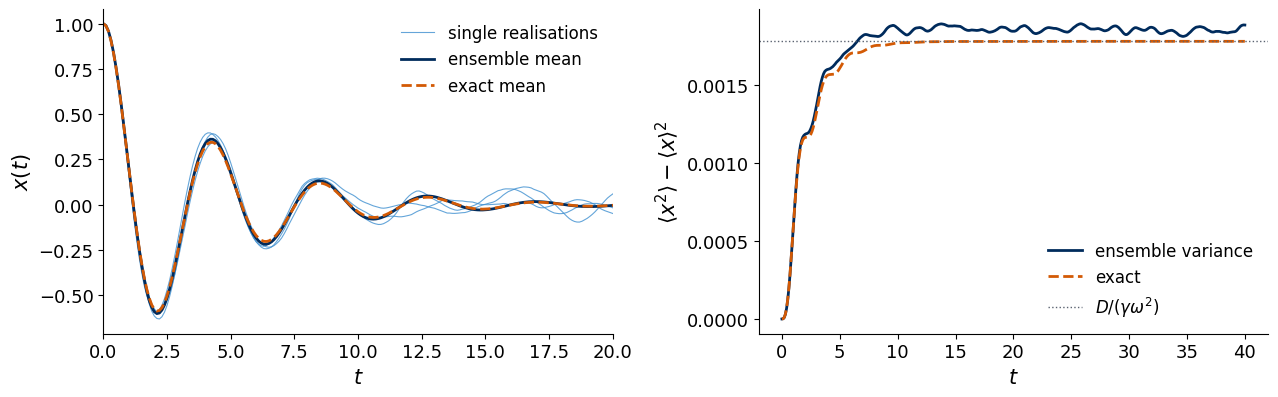

In [7]:
# one parameter point, 20 000 independent realisations up to t = 40
om_c, ga_c, n_ens = 1.5, 0.5, 20_000
ones = jnp.ones(n_ens)
X_ens, V_ens = simulate(om_c * ones, ga_c * ones, ones, 0 * ones, jax.random.key(0), n_sub=10, n_rec=401)
X_ens, V_ens = np.asarray(X_ens), np.asarray(V_ens)
t_ens = 10 * DT * np.arange(401)

# exact mean and exact variance of x(t) for the deterministic start (1, 0):
# Sigma(t) = Sigma_inf - e^{At} Sigma_inf e^{A^T t},  Sigma_inf = diag(D / (gamma omega^2), D / gamma)
A_c = np.asarray(drift_matrix(om_c, ga_c))
Sig_inf = np.diag([D_NOISE / (ga_c * om_c**2), D_NOISE / ga_c])
var_exact = np.array([(Sig_inf - scipy.linalg.expm(A_c * s) @ Sig_inf @ scipy.linalg.expm(A_c * s).T)[0, 0] for s in t_ens])
mean_exact = np.asarray(mean_trajectory(om_c, ga_c, 1.0, 0.0, jnp.asarray(t_ens)))
X_det = np.asarray(simulate(om_c * ones[:1], ga_c * ones[:1], ones[:1], 0 * ones[:1], jax.random.key(1), D=0.0, n_sub=10, n_rec=401)[0])[0]

# stationary covariance of the Euler-Maruyama recursion itself: Sigma = M Sigma M^T + Q dt (discrete Lyapunov equation)
M_c = np.eye(2) + A_c * DT
Sig_em = scipy.linalg.solve_discrete_lyapunov(M_c, np.diag([0, 2 * D_NOISE * DT]))

late = t_ens >= 30
var_x_meas, var_v_meas = X_ens[:, late].var(0).mean(), V_ens[:, late].var(0).mean()
print(f"max |ensemble mean - noise-free Euler recursion| = {np.abs(X_ens.mean(0) - X_det).max():.4f}"
      f"   (standard error of the mean ~ {np.sqrt(var_exact.max() / n_ens):.4f})")
print(f"max |noise-free Euler recursion - exact mean|  = {np.abs(X_det - mean_exact).max():.4f}   (time-discretisation error)")
print(f"<x^2>: exact D/(gamma omega^2) = {Sig_inf[0, 0]:.6f}, Euler-Maruyama recursion = {Sig_em[0, 0]:.6f}, "
      f"ensemble (t in [30, 40]) = {var_x_meas:.6f}")
print(f"<v^2>: exact D/gamma           = {Sig_inf[1, 1]:.6f}, Euler-Maruyama recursion = {Sig_em[1, 1]:.6f}, "
      f"ensemble (t in [30, 40]) = {var_v_meas:.6f}")
print(f"relative statistical error of one variance estimate ~ sqrt(2/N) = {np.sqrt(2 / n_ens):.3f}")
nums["em_var_x"] = {"exact": float(Sig_inf[0, 0]), "em_recursion": float(Sig_em[0, 0]), "ensemble": float(var_x_meas)}

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for i in range(3):
    axs[0].plot(t_ens, X_ens[i], color=UJSky, lw=0.8, alpha=0.8, label="single realisations" if i == 0 else None)
axs[0].plot(t_ens, X_ens.mean(0), color=UJNavy, label="ensemble mean")
axs[0].plot(t_ens, mean_exact, "--", color=DSOrange, label="exact mean")
axs[0].set_xlim(0, 20); axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$x(t)$"); axs[0].legend()
axs[1].plot(t_ens, X_ens.var(0), color=UJNavy, label="ensemble variance")
axs[1].plot(t_ens, var_exact, "--", color=DSOrange, label="exact")
axs[1].axhline(Sig_inf[0, 0], color=UJGray, lw=1, ls=":", label=r"$D/(\gamma\omega^2)$")
axs[1].set_xlabel("$t$"); axs[1].set_ylabel(r"$\langle x^2\rangle-\langle x\rangle^2$"); axs[1].legend()
plt.tight_layout(); plt.show()

The ensemble mean agrees with the noise-free Euler recursion to $7\times10^{-4}$, about two standard errors of the mean ($3\times10^{-4}$), as expected for the largest of 401 deviations. The recursion itself differs from the exact mean by up to $0.017$: this is the time-discretisation error of the Euler method, accumulated over 40 time units. The variances tell the same story. The ensemble gives $\langle x^2\rangle=0.001846$ and $\langle v^2\rangle=0.004166$; the stationary covariance of the Euler–Maruyama recursion predicts $0.001862$ and $0.004199$, within the statistical error of about 1%. Both lie about 5% above the exact values $D/(\gamma\omega^2)=0.001778$ and $D/\gamma=0.004000$ of the continuous equation, an error of order $\Delta t$ of the scheme, not of the sampling. In the right panel the variance grows from zero, as $\Sigma(t)$ predicts, and saturates at the stationary value after about 8 time units. For the noise level of our data, where the random force is a small perturbation, this accuracy is ample.

<hr/>
## 2. Trajectory data

Each trajectory of the data set has its own physical parameters and its own initial condition:
$\omega$ uniform in $[1,2]$; $\gamma$ log-uniform in $[0.2,6]$, i.e. $\ln\gamma$ uniform, so that every factor of $e$ in the friction is equally represented; $x_0$ uniform in $[0.5,1.5]$; $v_0$ uniform in $[-0.5,0.5]$. The noise strength $D=0.002$ is the same for all trajectories. Every trajectory is integrated with $\Delta t=0.01$ and recorded at 100 times $t_i=0.06\,i$, $i=0,\dots,99$, so the observation window is $[0,5.94]$. Both regimes are present: a trajectory is overdamped when $\gamma>2\omega$.

The ranges are a deliberate choice. Over the window the oscillation completes about one to two periods, and the initial position is always positive, so that a trajectory cannot be turned into another one by flipping its sign. Wider ranges, with many periods in the window or $x_0$ of both signs, make the task much harder for the network; Section 4.6 explains why. The quantities $x_0$ and $v_0$ are **nuisance factors**: they change the trajectory but are not properties of the oscillator. We call all four numbers $(\omega,\gamma,x_0,v_0)$ the *factors* of a trajectory.

In [8]:
OMEGA_RANGE = (1.0, 2.0)       # uniform
GAMMA_RANGE = (0.2, 6.0)       # log-uniform
X0_RANGE = (0.5, 1.5)          # uniform
V0_MAX = 0.5                   # v0 uniform in [-V0_MAX, V0_MAX]
N_SUB, T_POINTS = 6, 100       # record every 6th Euler-Maruyama step: 100 points, spacing 0.06
t_grid = N_SUB * DT * np.arange(T_POINTS)
FACTOR_NAMES = [r"$\omega$", r"$\ln\gamma$", r"$x_0$", r"$v_0$"]

def make_oscillator_data(n, seed, D=D_NOISE):
    """n noisy trajectories (n, 100) and their factors (n, 4) = (omega, gamma, x0, v0)."""
    rng = np.random.default_rng(seed)
    om = rng.uniform(*OMEGA_RANGE, n)
    ga = np.exp(rng.uniform(np.log(GAMMA_RANGE[0]), np.log(GAMMA_RANGE[1]), n))
    x0 = rng.uniform(*X0_RANGE, n)
    v0 = rng.uniform(-V0_MAX, V0_MAX, n)
    X, _ = simulate(*(jnp.asarray(a, jnp.float32) for a in (om, ga, x0, v0)), jax.random.key(seed), D=D,
                    n_sub=N_SUB, n_rec=T_POINTS)
    return np.asarray(X, np.float32), np.stack([om, ga, x0, v0], 1)

Xtr, Ftr = make_oscillator_data(20_000, seed=1)
Xte, Fte = make_oscillator_data(5_000, seed=2)
probe_factors = lambda F: np.stack([F[:, 0], np.log(F[:, 1]), F[:, 2], F[:, 3]], 1)   # omega, ln gamma, x0, v0
Pte = probe_factors(Fte)
over_te = Fte[:, 1] > 2 * Fte[:, 0]

# the noise: deviation of every test trajectory from its exact mean
Mte = np.asarray(mean_trajectories(*(jnp.asarray(a, jnp.float32) for a in Fte.T), jnp.asarray(t_grid)))
dev = Xte - Mte
print(f"training / test trajectories: {Xtr.shape} / {Xte.shape};  time window [0, {t_grid[-1]:.2f}]")
print(f"overdamped (gamma > 2 omega): {100 * (Ftr[:, 1] > 2 * Ftr[:, 0]).mean():.1f}% of the training set")
print(f"standard deviation of all positions: {Xtr.std():.3f};  rms deviation from the mean trajectory: {np.sqrt((dev**2).mean()):.4f}")
nums["data"] = {"n_train": int(Xtr.shape[0]), "n_test": int(Xte.shape[0]), "overdamped_frac": float((Ftr[:, 1] > 2 * Ftr[:, 0]).mean()),
                "x_std": float(Xtr.std()), "noise_rms": float(np.sqrt((dev**2).mean()))}

training / test trajectories: (20000, 100) / (5000, 100);  time window [0, 5.94]
overdamped (gamma > 2 omega): 20.9% of the training set
standard deviation of all positions: 0.430;  rms deviation from the mean trajectory: 0.0314


Of the training trajectories 20.9% are overdamped. The positions have a standard deviation of 0.430 over the data set, while the random force moves a trajectory away from its mean by 0.031 (root mean square over all times and test trajectories): the noise is a small but visible perturbation, about 7% of the signal.

The figure shows test trajectories selected so that only one parameter varies: on the left $\gamma\approx0.4$, $x_0\approx1$, $v_0\approx0$ with $\omega$ from 1 to 2, on the right $\omega\approx1.5$ with $\gamma$ from $0.25$ to $5.5$. The small wiggles are the random force.

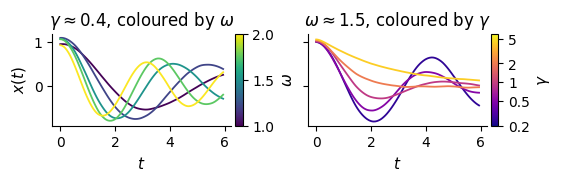

In [9]:
def pick(mask, key, targets):
    """Indices of the test trajectories inside mask whose factor `key` is closest to each target value."""
    idx = np.flatnonzero(mask)
    return [idx[np.argmin(np.abs(Fte[idx, key] - tv))] for tv in targets]

near = lambda k, lo, hi: (Fte[:, k] >= lo) & (Fte[:, k] <= hi)
sel_w = pick(near(1, 0.3, 0.45) & near(2, 0.9, 1.1) & near(3, -0.1, 0.1), 0, np.linspace(1.0, 2.0, 5))
sel_g = pick(near(0, 1.4, 1.6) & near(2, 0.9, 1.1) & near(3, -0.1, 0.1), 1, np.exp(np.linspace(np.log(0.25), np.log(5.5), 5)))
norm_w, norm_g = Normalize(*OMEGA_RANGE), mpl.colors.LogNorm(*GAMMA_RANGE)

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.7), sharey=True)
    for i in sel_w:
        axs[0].plot(t_grid, Xte[i], color=plt.cm.viridis(norm_w(Fte[i, 0])), lw=1.3)
    for i in sel_g:
        axs[1].plot(t_grid, Xte[i], color=plt.cm.plasma(norm_g(Fte[i, 1]) * 0.9), lw=1.3)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm_w, "viridis"), ax=axs[0], pad=0.02, aspect=12); cb.set_label(r"$\omega$")
    cb = fig.colorbar(plt.cm.ScalarMappable(norm_g, "plasma"), ax=axs[1], pad=0.02, aspect=12); cb.set_label(r"$\gamma$")
    cb.set_ticks([0.2, 0.5, 1, 2, 5]); cb.set_ticklabels(["0.2", "0.5", "1", "2", "5"]); cb.minorticks_off()
    axs[0].set_title(r"$\gamma\approx0.4$, coloured by $\omega$"); axs[1].set_title(r"$\omega\approx1.5$, coloured by $\gamma$")
    for a in axs: a.set_xlabel("$t$")
    axs[0].set_ylabel("$x(t)$")
    save(fig, "gen_traj_data.png"); plt.show()

<hr/>
## 3. A β-VAE for trajectories

### 3.1 Gaussian likelihood and the β-VAE loss

We use the notation of Labs 024 and 026. A trajectory $\mathbf x=(x(t_1),\dots,x(t_T))\in\mathbb R^T$, $T=100$, is described by a latent vector $\mathbf z\in\mathbb R^d$ with the prior $p(\mathbf z)=\mathcal N(0,I_d)$. The encoder returns a Gaussian $q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\mathrm{diag}\,\boldsymbol\sigma^2_\phi(\mathbf x)\big)$, and the decoder a probability distribution of trajectories $p_\theta(\mathbf x|\mathbf z)$.

The pixels of MNIST were described by Bernoulli distributions. Positions are real numbers, and the natural choice is a **Gaussian likelihood**: given $\mathbf z$, every recorded position is Gaussian around the value $\hat x_i=G_\theta(\mathbf z)_i$ of a decoder network, with a fixed standard deviation $\sigma_x$,
$$\begin{aligned}
p_\theta(\mathbf x|\mathbf z)&=\prod_{i=1}^T\frac{1}{\sqrt{2\pi\sigma_x^2}}\exp\Big[-\frac{(x_i-\hat x_i)^2}{2\sigma_x^2}\Big],\\
-\log p_\theta(\mathbf x|\mathbf z)&=\frac{1}{2\sigma_x^2}\sum_{i=1}^T(x_i-\hat x_i)^2+\frac T2\log(2\pi\sigma_x^2).
\end{aligned}$$
The reconstruction term of the loss is therefore the sum of squared errors divided by $2\sigma_x^2$, i.e. the mean squared error $\mathrm{MSE}=\frac1T\sum_i(x_i-\hat x_i)^2$ scaled by $T/(2\sigma_x^2)$, plus a constant that does not affect training. The decoder output $G_\theta(\mathbf z)$ is the mean of the trajectory given $\mathbf z$: a smooth curve, without the noise. The scale $\sigma_x$ says how large a deviation the model tolerates; we take $\sigma_x=0.1$, about three times the typical deviation of a noisy trajectory from its mean (0.031, Section 2), so that the model gains little by storing the noise.

The $\beta$-VAE loss of Lab 026 is
$$\begin{aligned}
\mathcal L_\beta(\mathbf x)&=\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\Big[\frac{1}{2\sigma_x^2}\big\lVert\mathbf x-G_\theta(\mathbf z)\big\rVert^2\Big]}_{\text{distortion}}
+\beta\,\underbrace{\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)}_{\text{rate}},\\
\mathrm{KL}&=\frac12\sum_{k=1}^d\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big).
\end{aligned}$$
The Kullback–Leibler (KL) divergence measures, in nats, how much the encoder's distribution for one trajectory differs from the prior; it is the price of the information the code carries about the trajectory. With $\beta=1$ the loss is minus the evidence lower bound (ELBO) of Lab 024; $\beta>1$ makes information more expensive and pushes towards fewer and more independent coordinates. Only the product $2\sigma_x^2\beta$ matters for the trade-off: doubling $\sigma_x^2$ has the same effect as doubling $\beta$. The expectation over $q_\phi$ is estimated with one sample $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$, $\boldsymbol\varepsilon\sim\mathcal N(0,I)$ (reparametrisation trick).

### 3.2 Network

A trajectory is a short vector of 100 numbers, and a dense network is enough. The table lists the shapes for a minibatch of $B$ trajectories; ReLU denotes the rectified linear unit $\max(0,u)$, applied elementwise.

| quantity | shape | layer |
|---|---|---|
| input $\mathbf x$ | $(B,100)$ | |
| encoder hidden layers | $(B,256)\to(B,128)$ | dense + ReLU |
| $\boldsymbol\mu$, $\log\boldsymbol\sigma^2$ | $(B,8)$ each | two linear heads |
| $\boldsymbol\varepsilon$, $\mathbf z$ | $(B,8)$ | $\mathbf z=\boldsymbol\mu+e^{\frac12\log\boldsymbol\sigma^2}\odot\boldsymbol\varepsilon$ |
| decoder hidden layers | $(B,128)\to(B,256)$ | dense + ReLU |
| mean trajectory $G_\theta(\mathbf z)$ | $(B,100)$ | linear |

The latent dimension $d=8$ is twice the number of factors, so the network has room to spare and the coordinates it switches off tell us how many it needs. The class takes the input length as an argument; Section 6 uses it for two masses with 200 inputs. The output of `nnx.tabulate` lists every layer with its parameters.

In [10]:
SIGMA_X = 0.1        # standard deviation of the Gaussian decoder p_theta(x | z)

class TrajVAE(nnx.Module):
    """Dense VAE for trajectories with n_in numbers.
    encoder: x (B, n_in) -> 256 -> 128 -> mu (B, d), logvar (B, d)
    decoder: z (B, d)    -> 128 -> 256 -> mean trajectory (B, n_in)"""
    def __init__(self, n_in, d, hidden=(256, 128), *, rngs):
        h1, h2 = hidden
        self.enc1, self.enc2 = nnx.Linear(n_in, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs)
        self.mu, self.logvar = nnx.Linear(h2, d, rngs=rngs), nnx.Linear(h2, d, rngs=rngs)     # two heads
        self.dec1, self.dec2 = nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs)
        self.dec3 = nnx.Linear(h1, n_in, rngs=rngs)                                            # linear output

    def encode(self, x):
        """q_phi(z | x) = N(mu, diag exp(logvar)): returns (mu, logvar), each (B, d)."""
        h = nnx.relu(self.enc2(nnx.relu(self.enc1(x))))
        return self.mu(h), self.logvar(h)

    def decode(self, z):
        """Mean trajectory G_theta(z), (B, n_in)."""
        return self.dec3(nnx.relu(self.dec2(nnx.relu(self.dec1(z)))))

    def __call__(self, x):
        """Deterministic reconstruction G_theta(mu(x)), used for the summary table."""
        return self.decode(self.encode(x)[0])

def kl_per_dim(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) for every latent coordinate; same shape as mu."""
    return 0.5 * (mu**2 + jnp.exp(logvar) - logvar - 1)

def reparametrise(mu, logvar, key):
    """z = mu + sigma * eps, eps ~ N(0, I)."""
    return mu + jnp.exp(0.5 * logvar) * jax.random.normal(key, mu.shape)

def beta_vae_loss(model, batch, key, beta):
    """beta-VAE loss per trajectory, averaged over the minibatch; the constant (T/2) ln(2 pi sigma_x^2) is dropped."""
    x = batch[0]
    mu, logvar = model.encode(x)
    z = reparametrise(mu, logvar, key)
    rec = ((model.decode(z) - x) ** 2).sum(-1).mean() / (2 * SIGMA_X**2)
    kl = kl_per_dim(mu, logvar).sum(-1).mean()
    return rec + beta * kl, {"loss": rec + beta * kl, "rec": rec, "kl": kl}

D_LATENT = 8
_m = TrajVAE(T_POINTS, D_LATENT, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(jnp.asarray(Xtr[:5]))
assert _mu.shape == _lv.shape == (5, D_LATENT) and _m.decode(_mu).shape == (5, T_POINTS)
print(nnx.tabulate(_m, jnp.asarray(Xtr[:1]), depth=1))

                                 TrajVAE Summary                                 
┏━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path   ┃ type    ┃ inputs         ┃ outputs        ┃ Param                    ┃
┡━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encode │ TrajVAE │ float32[1,100] │ - float32[1,8] │ 120,692 (482.8 KB)       │
│        │         │                │ - float32[1,8] │                          │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ enc1   │ Linear  │ float32[1,100] │ float32[1,256] │ bias: float32[256]       │
│        │         │                │                │ kernel: float32[100,256] │
│        │         │                │                │                          │
│        │         │                │                │ 25,856 (103.4 KB)        │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ enc2   │ Linear  │ float32[1,256] │ float32[1,128] │ bias: float32[128]       │
│        │         │                │                │ kernel: float32[256,128] │
│        │         │                │                │                          │
│        │         │                │                │ 32,896 (131.6 KB)        │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ mu     │ Linear  │ float32[1,128] │ float32[1,8]   │ bias: float32[8]         │
│        │         │                │                │ kernel: float32[128,8]   │
│        │         │                │                │                          │
│        │         │                │                │ 1,032 (4.1 KB)           │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ logvar │ Linear  │ float32[1,128] │ float32[1,8]   │ bias: float32[8]         │
│        │         │                │                │ kernel: float32[128,8]   │
│        │         │                │                │                          │
│        │         │                │                │ 1,032 (4.1 KB)           │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ decode │ TrajVAE │ float32[1,8]   │ float32[1,100] │ 120,692 (482.8 KB)       │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ dec1   │ Linear  │ float32[1,8]   │ float32[1,128] │ bias: float32[128]       │
│        │         │                │                │ kernel: float32[8,128]   │
│        │         │                │                │                          │
│        │         │                │                │ 1,152 (4.6 KB)           │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ dec2   │ Linear  │ float32[1,128] │ float32[1,256] │ bias: float32[256]       │
│        │         │                │                │ kernel: float32[128,256] │
│        │         │                │                │                          │
│        │         │                │                │ 33,024 (132.1 KB)        │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│ dec3   │ Linear  │ float32[1,256] │ float32[1,100] │ bias: float32[100]       │
│        │         │                │                │ kernel: float32[256,100] │
│        │         │                │                │                          │
│        │         │                │                │ 25,700 (102.8 KB)        │
├────────┼─────────┼────────────────┼────────────────┼──────────────────────────┤
│        │         │                │          Total │ 120,692 (482.8 KB)       │
└────────┴─────────┴────────────────┴────────────────┴──────────────────────────┘
                                                                                 
                      Total Parameters: 120,692 (482.8 KB)                       

The table is precise but hides the structure. The function `draw_network` draws a network as columns of nodes joined by edges; a column with more neurons than can be drawn shows a few and an ellipsis, and its label gives the true number. During **training** (top) a trajectory passes through the encoder to $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, a sample $\mathbf z$ is drawn from $q_\phi(\mathbf z|\mathbf x)$, and the decoder maps it back to a mean trajectory. For **generation** (bottom) the encoder is not used: $\mathbf z$ is drawn from the prior $\mathcal N(0,I)$ and decoded.

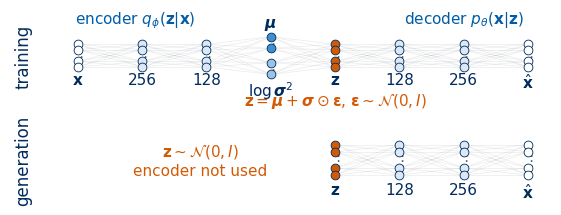

In [11]:
def draw_network(ax, columns, x_gap=1.0, node_r=0.11, max_nodes=6, y_gap=0.3, edge_alpha=0.12, label_size=11, x_offset=0.0,
                 node_size=40):
    """Draw a feed-forward network as columns of nodes joined by edges.

    columns: list of columns from left to right. A column is a list of groups stacked vertically; a group is a dict
        n      - number of neurons it stands for (at most max_nodes, or `show`, are drawn; an ellipsis marks the others),
        color  - node colour,
        label  - text under the column; in a column of two groups, above the first and below the second group,
        edges  - False to draw no edges into this group (e.g. the noise eps that only enters z).
    Edges join every drawn node of a column with every drawn node of the next column, except groups with edges=False.
    Returns the list of node positions per column, for annotations."""
    positions = []
    for c, groups in enumerate(columns):
        x = x_offset + c * x_gap
        n_shown = [gr.get("show", min(gr["n"], max_nodes)) for gr in groups]
        heights = [s * y_gap + (0.25 if gr["n"] > s else 0) for gr, s in zip(groups, n_shown)]
        y_top = (sum(heights) + 0.35 * (len(groups) - 1)) / 2           # centre the column at y = 0
        col_pos = []
        for g_i, (gr, h, shown) in enumerate(zip(groups, heights, n_shown)):
            ys = y_top - y_gap / 2 - y_gap * np.arange(shown)
            if gr["n"] > shown:                                          # leave a gap for the ellipsis
                ys[shown // 2:] -= 0.25
                ax.text(x, (ys[shown // 2 - 1] + ys[shown // 2]) / 2, r"$\vdots$", ha="center", va="center",
                        fontsize=label_size, color=UJGray)
            ax.scatter(np.full_like(ys, x), ys, s=node_size, facecolor=gr["color"], edgecolor=UJNavy, lw=0.6, zorder=3)  # round nodes
            if gr.get("label"):
                if g_i == len(groups) - 1:                                   # label below the (last) group
                    ax.text(x, ys[-1] - 0.2, gr["label"], ha="center", va="top", fontsize=label_size, color=UJNavy)
                else:                                                        # label above the first of two groups
                    ax.text(x, ys[0] + 0.2, gr["label"], ha="center", va="bottom", fontsize=label_size, color=UJNavy)
            col_pos.append([(x, y, gr.get("edges", True)) for y in ys])
            y_top -= h + 0.35
        positions.append(col_pos)
    for left, right in zip(positions[:-1], positions[1:]):              # edges between neighbouring columns
        for (x1, y1, _) in [p for gr in left for p in gr]:
            for (x2, y2, e) in [p for gr in right for p in gr]:
                if e:
                    ax.plot([x1, x2], [y1, y2], color=UJGray, lw=0.5, alpha=edge_alpha, zorder=1)
    ax.axis("off")
    return positions

UJLight = "#DCE8F5"      # hidden layers

def vae_columns(n_in, hidden, d, in_label=r"$\mathbf{x}$", out_label=r"$\hat{\mathbf{x}}$", train=True):
    """Columns of a dense VAE: training (x -> encoder -> mu, log sigma^2 -> z -> decoder) or generation (z -> decoder)."""
    h1, h2 = hidden
    enc = [[dict(n=n_in, color="white", label=in_label)], [dict(n=h1, color=UJLight, label=str(h1))],
           [dict(n=h2, color=UJLight, label=str(h2))],
           [dict(n=d, color=UJSky, label=r"$\boldsymbol{\mu}$", show=min(d, 2)),
            dict(n=d, color="#9CC3E6", label=r"$\log\boldsymbol{\sigma}^2$", show=min(d, 2))]]
    z = [[dict(n=d, color=DSOrange, label=r"$\mathbf{z}$")]]
    dec = [[dict(n=h2, color=UJLight, label=str(h2))], [dict(n=h1, color=UJLight, label=str(h1))],
           [dict(n=n_in, color="white", label=out_label)]]
    return enc + z + dec if train else z + dec

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.0), layout="none")
    axs = fig.subplots(2, 1, gridspec_kw=dict(height_ratios=[1.35, 1]))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0)
    XG = 0.95
    draw_network(axs[0], vae_columns(T_POINTS, (256, 128), D_LATENT), x_gap=XG, max_nodes=4, y_gap=0.22, node_r=0.09)
    axs[0].text(4 * XG, -1.4, r"$\mathbf{z}=\boldsymbol{\mu}+\boldsymbol{\sigma}\odot\boldsymbol{\varepsilon}$, "
                r"$\boldsymbol{\varepsilon}\sim\mathcal{N}(0,I)$", ha="center", va="top", fontsize=11, color=DSOrange)
    axs[0].text(0.9 * XG, 1.3, r"encoder $q_\phi(\mathbf{z}|\mathbf{x})$", ha="center", fontsize=11, color=UJBlue)
    axs[0].text(6 * XG, 1.3, r"decoder $p_\theta(\mathbf{x}|\mathbf{z})$", ha="center", fontsize=11, color=UJBlue)
    axs[0].text(-0.8, 0, "training", rotation=90, ha="center", va="center", fontsize=12, color=UJNavy)
    axs[0].set_ylim(-1.8, 1.65)
    draw_network(axs[1], vae_columns(T_POINTS, (256, 128), D_LATENT, train=False), x_gap=XG, max_nodes=4, y_gap=0.22,
                 node_r=0.09, x_offset=4 * XG)
    axs[1].text(1.9 * XG, 0, r"$\mathbf{z}\sim\mathcal{N}(0,I)$" + "\nencoder not used", ha="center", va="center",
                fontsize=11, color=DSOrange)
    axs[1].text(-0.8, 0, "generation", rotation=90, ha="center", va="center", fontsize=12, color=UJNavy)
    axs[1].set_ylim(-1.15, 0.75)
    for a in axs: a.set_xlim(-1.0, 7 * XG + 0.35)
    save(fig, "gen_traj_arch.png"); plt.show()

### 3.3 Training

All models are trained by the same function, adapted from Lab 024: Adam (adaptive moment estimation, the gradient method that rescales each parameter's step by running averages of its gradient and squared gradient) with learning rate $10^{-3}$, minibatches of 128, one jit-compiled `lax.scan` per epoch. If a checkpoint file exists, the parameters are loaded instead.

We train $\beta\in\{0.5,1,4,8\}$, each with three random seeds, for 80 epochs over the 20 000 training trajectories. Several seeds are needed because the outcome of unsupervised disentangling depends on the initialisation [Locatello *et al.* 2019]. After training we compute, on the 5000 test trajectories, the rate $R$ (KL per trajectory) and the distortion (the reconstruction term with one sample $\mathbf z$), both in nats. As a reference we also compute the reconstruction term of the exact mean trajectory, $\frac{1}{2\sigma_x^2}\lVert\mathbf x-\langle\mathbf x\rangle\rVert^2$: a model that knew the four factors perfectly and nothing about the noise would reach this value.

In [12]:
def train(make_model, loss_fn, data, epochs, seed, name, batch_size=128, lr=1e-3, log_every=50):
    """Adam, one jit-compiled lax.scan per epoch; data = tuple of arrays with the same first dimension.
    Loads the stored parameters if they exist, otherwise trains and saves them."""
    model = make_model(seed)
    path = f"{CKPT}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as fh:
            saved = pickle.load(fh)
        state = nnx.state(model, nnx.Param)
        nnx.replace_by_pure_dict(state, saved["params"])
        nnx.update(model, state)
        return model, saved["history"]

    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n = data[0].shape[0]
    n_batches = n // batch_size
    data = tuple(jnp.asarray(a) for a in data)

    def batch_loss(params, batch, key):
        return loss_fn(nnx.merge(graphdef, params, rest), batch, key)

    @jax.jit
    def train_epoch(params, opt_state, key):
        k_perm, k_steps = jax.random.split(key)
        idx = jax.random.permutation(k_perm, n)[: n_batches * batch_size].reshape(n_batches, batch_size)
        def step(carry, inp):
            params, opt_state = carry
            batch_idx, k = inp
            (loss, aux), grads = jax.value_and_grad(batch_loss, has_aux=True)(params, tuple(a[batch_idx] for a in data), k)
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), opt_state), aux
        (params, opt_state), aux = jax.lax.scan(step, (params, opt_state), (idx, jax.random.split(k_steps, n_batches)))
        return params, opt_state, jax.tree.map(jnp.mean, aux)

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, aux = train_epoch(params, opt_state, sub)
        history.append({k: float(v) for k, v in aux.items()})
        if (ep + 1) % log_every == 0 or ep + 1 == epochs:
            print(f"  {name} epoch {ep + 1:3d}: " + "  ".join(f"{k} {v:.3f}" for k, v in history[-1].items())
                  + f"   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params)
    history = {k: np.array([h[k] for h in history]) for k in history[0]}
    with open(path, "wb") as fh:
        pickle.dump({"params": jax.tree.map(np.asarray, nnx.to_pure_dict(nnx.state(model, nnx.Param))),
                     "history": history}, fh)
    return model, history

encode = nnx.jit(lambda m, x: m.encode(x))
decode = nnx.jit(lambda m, z: m.decode(z))

In [13]:
BETAS, SEEDS, EPOCHS = [0.5, 1, 4, 8], [0, 1, 2], 80
t0 = time.time()
vaes = {}
for beta in BETAS:
    for seed in SEEDS:
        vaes[beta, seed], _ = train(lambda s: TrajVAE(T_POINTS, D_LATENT, rngs=nnx.Rngs(s)),
                                    partial(beta_vae_loss, beta=beta), (Xtr,), EPOCHS, seed,
                                    name=f"lab028_osc_beta{beta}_seed{seed}")
print(f"{len(vaes)} models ready in {time.time() - t0:.0f} s")

def evaluate(model, X, key=jax.random.key(99)):
    """Posterior means, log-variances, and test rate R and distortion D_rec (nats per trajectory, one z sample)."""
    mu, lv = (np.asarray(a) for a in encode(model, jnp.asarray(X)))
    z = np.asarray(reparametrise(jnp.asarray(mu), jnp.asarray(lv), key))
    rec = ((np.asarray(decode(model, jnp.asarray(z))) - X) ** 2).sum(-1) / (2 * SIGMA_X**2)
    return mu, lv, float(kl_per_dim(mu, lv).sum(-1).mean()), float(rec.mean())

ev = {key: evaluate(m, Xte) for key, m in vaes.items()}
floor = ((dev**2).sum(-1) / (2 * SIGMA_X**2)).mean()
print(f"reconstruction term of the exact mean trajectory (noise floor): {floor:.2f} nats")
print("beta  seed   rate R   distortion")
for (beta, seed), (_, _, R, Drec) in ev.items():
    print(f"{beta:4}  {seed:4}  {R:7.2f}  {Drec:9.2f}")
nums["noise_floor"] = float(floor)

12 models ready in 0 s


reconstruction term of the exact mean trajectory (noise floor): 4.93 nats
beta  seed   rate R   distortion
 0.5     0    10.58       2.17
 0.5     1    10.31       1.97
 0.5     2    10.47       1.88
   1     0     8.83       3.31
   1     1     8.61       3.23
   1     2     8.66       2.97
   4     0     6.00       9.21
   4     1     6.00       8.59
   4     2     5.97       8.66
   8     0     4.74      14.84
   8     1     4.83      14.69
   8     2     4.71      15.39


The rate falls and the distortion grows with $\beta$, as in Lab 026: from $R\approx10.3$–$10.6$ nats and a distortion of $1.9$–$2.2$ nats at $\beta=0.5$ to $R\approx4.7$–$4.8$ nats and $14.7$–$15.4$ nats at $\beta=8$; the three seeds agree to a few tenths of a nat. For $\beta\le1$ the distortion lies **below** the noise floor of 4.93 nats: the decoder reproduces part of the random wiggles of the individual trajectory, which it can do only if the code stores information about that particular noise realisation. For $\beta=4$ and $\beta=8$ the distortion lies above the floor, and the code describes smooth trajectories.

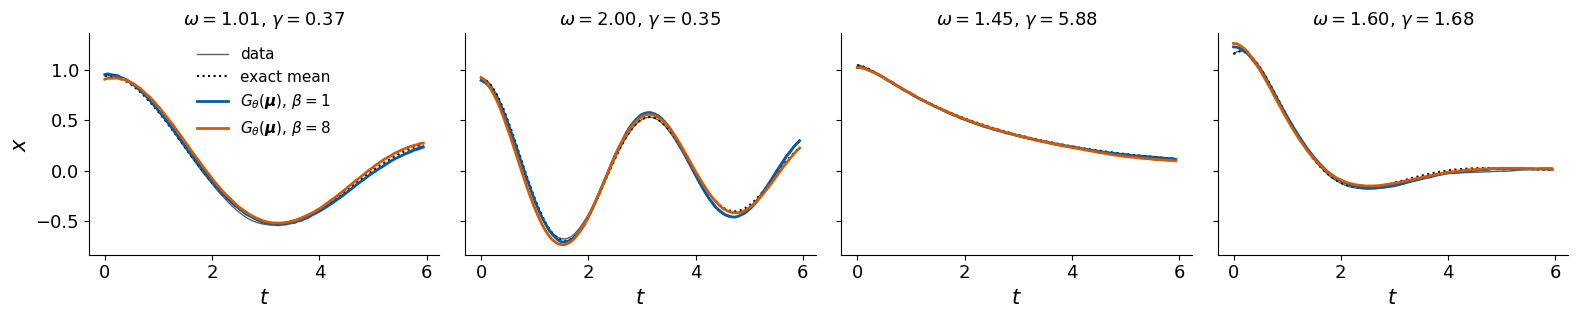

In [14]:
show_i = [sel_w[0], sel_w[-1], sel_g[-1], int(np.flatnonzero(near(3, 0.4, 0.5))[0])]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for a, i in zip(axs, show_i):
    a.plot(t_grid, Xte[i], color=UJGray, lw=1, label="data")
    a.plot(t_grid, Mte[i], ":", color="k", lw=1.5, label="exact mean")
    for beta, col in [(1, UJBlue), (8, DSOrange)]:
        a.plot(t_grid, np.asarray(decode(vaes[beta, 0], jnp.asarray(ev[beta, 0][0][i:i + 1])))[0], color=col,
               label=rf"$G_\theta(\boldsymbol{{\mu}})$, $\beta={beta}$")
    a.set_title(rf"$\omega={Fte[i, 0]:.2f}$, $\gamma={Fte[i, 1]:.2f}$", fontsize=13); a.set_xlabel("$t$")
axs[0].set_ylabel("$x$"); axs[0].legend(fontsize=11)
plt.tight_layout(); plt.show()

At $\beta=1$ and at $\beta=8$ the reconstructions $G_\theta(\boldsymbol\mu)$ are smooth curves that lie on the exact mean trajectory (dotted) rather than on the noisy data: the decoder returns the mean, and at these noise levels the difference between the two values of $\beta$ is hardly visible by eye. The four examples cover a slow and a fast underdamped oscillation, an overdamped creep and a trajectory with a large initial velocity. The numbers of the table above are the more sensitive measure.

<hr/>
## 4. Latent coordinates and physical parameters

We now read the latent codes, following the protocol of the lecture: first find the coordinates that carry information, then compare them with the known factors through correlations and the mutual information gap, then decode traversals, and finally ask why the result looks as it does.

### 4.1 Active coordinates

A coordinate whose posterior equals the prior for every trajectory carries no information. Its average KL,
$$\overline{\mathrm{KL}}_k=\Big\langle\tfrac12\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)\Big\rangle_{\mathbf x},$$
measures in nats how much coordinate $k$ is used. We call a coordinate **active** if $\overline{\mathrm{KL}}_k>0.1$ nats, as in Lab 026.

In [15]:
ACTIVE_NATS = 0.1
kl_dims = {key: np.asarray(kl_per_dim(e[0], e[1])).mean(0) for key, e in ev.items()}
active = {key: np.flatnonzero(k > ACTIVE_NATS) for key, k in kl_dims.items()}
print("mean KL per coordinate (nats), sorted; active coordinates:")
for key in vaes:
    print(f"beta {key[0]:3}, seed {key[1]}:", np.round(np.sort(kl_dims[key])[::-1], 2), "  active:", len(active[key]))
nums["n_active"] = {str(b): [int(len(active[b, s])) for s in SEEDS] for b in BETAS}

mean KL per coordinate (nats), sorted; active coordinates:
beta 0.5, seed 0: [3.03 2.62 2.59 1.67 0.66 0.   0.   0.  ]   active: 5
beta 0.5, seed 1: [3.44 3.44 2.11 0.89 0.42 0.   0.   0.  ]   active: 5
beta 0.5, seed 2: [3.11 3.07 2.63 1.4  0.25 0.   0.   0.  ]   active: 5
beta   1, seed 0: [2.53 2.51 2.28 1.46 0.05 0.   0.   0.  ]   active: 4
beta   1, seed 1: [3.17 3.07 1.67 0.69 0.   0.   0.   0.  ]   active: 4
beta   1, seed 2: [2.89 2.73 2.27 0.76 0.   0.   0.   0.  ]   active: 4
beta   4, seed 0: [2.7  1.28 0.97 0.93 0.13 0.   0.   0.  ]   active: 5
beta   4, seed 1: [2.5  2.3  0.97 0.23 0.   0.   0.   0.  ]   active: 4
beta   4, seed 2: [2.28 1.97 1.5  0.22 0.   0.   0.   0.  ]   active: 4
beta   8, seed 0: [2.32 1.7  0.64 0.08 0.   0.   0.   0.  ]   active: 3
beta   8, seed 1: [2.37 1.77 0.62 0.07 0.   0.   0.   0.  ]   active: 3
beta   8, seed 2: [2.33 1.71 0.6  0.07 0.   0.   0.   0.  ]   active: 3


The number of active coordinates is five at $\beta=0.5$, four at $\beta=1$, four or five at $\beta=4$ and three at $\beta=8$; the remaining coordinates carry less than $0.01$ nats and are switched off. For $\beta$ between 1 and 4 the count equals the number of factors, four: without being told, the network finds how many numbers describe a trajectory. The fifth coordinate at $\beta=0.5$ (0.25–0.66 nats) and the fifth at $\beta=4$, seed 0 (0.13 nats) carry little, consistent with stored noise. At $\beta=8$ the fourth coordinate keeps only 0.07–0.08 nats, below the threshold: one factor has been dropped, and Section 4.3 shows which.

### 4.2 Correlations and the mutual information gap

The first probe is the Pearson correlation between the latent mean $\mu_k(\mathbf x)$ and a factor $v$ over the test set,
$$\rho(\mu_k,v)=\frac{\langle\mu_kv\rangle-\langle\mu_k\rangle\langle v\rangle}{\sqrt{\mathrm{Var}\,\mu_k\,\mathrm{Var}\,v}}\in[-1,1].$$
It detects linear relations; we correlate with $\ln\gamma$ rather than $\gamma$ because $\gamma$ spans a factor of 30 and was drawn uniformly in $\ln\gamma$. The sign of a coordinate is arbitrary, so we look at $|\rho|$.

The second probe is the mutual information gap (MIG) of Lab 026 [Chen *et al.* 2018], which also sees nonlinear relations. The mutual information $I(z;v)=H(z)+H(v)-H(z,v)$, with $H$ the Shannon entropy, measures in nats how much knowing $z$ reduces the uncertainty about $v$. For each factor $v_k$ let $j_1^{(k)}$ and $j_2^{(k)}$ be the coordinates with the largest and the second-largest mutual information with it; then
$$\mathrm{MIG}=\frac1K\sum_{k=1}^K\frac{I\big(\mu_{j_1^{(k)}};v_k\big)-I\big(\mu_{j_2^{(k)}};v_k\big)}{H(v_k)}.$$
A factor stored in exactly one coordinate contributes a gap close to 1; a factor shared by two coordinates, or not stored, contributes close to 0. The quantities are estimated from histograms: the latent means in 20 equal-width bins, the continuous factors in 20 bins of equal population, so that $H(v_k)=\ln20$. We use only the active coordinates: an inactive coordinate is replaced by a sample of $\mathcal N(0,1)$ before decoding, so whatever its mean contains cannot reach the decoder. Even a perfect code does not reach 1 with this estimator, because the bins of $\mu_j$ and of $v_k$ do not coincide; the cell therefore also evaluates the MIG of the true factors and of the factors with $\omega$ and $x_0$ mixed by a rotation of $45^\circ$.

In [16]:
def abs_corr(mu, P):
    """|Pearson correlation| between every latent mean (columns of mu) and every factor (columns of P): (d, K)."""
    d = mu.shape[1]
    return np.nan_to_num(np.abs(np.corrcoef(np.c_[mu, P].T)[:d, d:]))

N_BINS = 20
def bins_equal_width(v):
    return np.clip(((v - v.min()) / (v.max() - v.min() + 1e-12) * N_BINS).astype(int), 0, N_BINS - 1)
def bins_quantile(v):
    return np.searchsorted(np.quantile(v, np.linspace(0, 1, N_BINS + 1)[1:-1]), v)
def entropy(labels):
    p = np.bincount(labels) / len(labels); p = p[p > 0]
    return float(-(p * np.log(p)).sum())
def mutual_information(a, b):
    return entropy(a) + entropy(b) - entropy(a * N_BINS + b)

def mig(mu, P, act):
    """Mutual information gap per factor and its mean; latent means of the active coordinates in 20 equal-width bins,
    factors in 20 equal-population bins (entropy ln 20)."""
    zb = [bins_equal_width(mu[:, j]) for j in act]
    gaps = []
    for k in range(P.shape[1]):
        vb = bins_quantile(P[:, k])
        I = sorted([mutual_information(z, vb) for z in zb] + [0.0, 0.0], reverse=True)
        gaps.append((I[0] - I[1]) / entropy(vb))
    return np.array(gaps)

corr = {key: abs_corr(ev[key][0], Pte) for key in vaes}
migs = {key: mig(ev[key][0], Pte, active[key]) for key in vaes}
print("MIG per factor (omega, ln gamma, x0, v0) and mean:")
for key in vaes:
    print(f"beta {key[0]:3}, seed {key[1]}:", np.round(migs[key], 3), f"  mean {migs[key].mean():.3f}")

# a sanity check of the estimator: the factors themselves, and the factors mixed by a rotation
P_rot = Pte.copy(); s = (Pte - Pte.mean(0)) / Pte.std(0)
P_rot[:, 0], P_rot[:, 2] = (s[:, 0] + s[:, 2]) / np.sqrt(2), (s[:, 0] - s[:, 2]) / np.sqrt(2)
print(f"MIG of the true factors: {mig(Pte, Pte, range(4)).mean():.3f};  omega and x0 rotated by 45 degrees: "
      f"{mig(P_rot, Pte, range(4)).mean():.3f}")
nums["mig"] = {str(b): [float(migs[b, s].mean()) for s in SEEDS] for b in BETAS}
nums["mig_true"] = float(mig(Pte, Pte, range(4)).mean()); nums["mig_rot"] = float(mig(P_rot, Pte, range(4)).mean())

MIG per factor (omega, ln gamma, x0, v0) and mean:
beta 0.5, seed 0: [0.025 0.032 0.001 0.047]   mean 0.026
beta 0.5, seed 1: [0.002 0.079 0.028 0.111]   mean 0.055
beta 0.5, seed 2: [0.043 0.088 0.012 0.023]   mean 0.042
beta   1, seed 0: [0.033 0.047 0.046 0.016]   mean 0.036
beta   1, seed 1: [0.014 0.101 0.036 0.112]   mean 0.066
beta   1, seed 2: [0.055 0.114 0.002 0.074]   mean 0.062
beta   4, seed 0: [0.055 0.069 0.008 0.056]   mean 0.047
beta   4, seed 1: [0.024 0.054 0.009 0.074]   mean 0.040
beta   4, seed 2: [0.047 0.088 0.043 0.063]   mean 0.060
beta   8, seed 0: [0.05  0.094 0.03  0.002]   mean 0.044
beta   8, seed 1: [0.036 0.061 0.025 0.003]   mean 0.031
beta   8, seed 2: [0.055 0.094 0.022 0.005]   mean 0.044
MIG of the true factors: 0.916;  omega and x0 rotated by 45 degrees: 0.462


The estimator gives 0.916 for the true factors rather than 1, because of the binning, and 0.462 when $\omega$ and $x_0$ are mixed by the rotation: mixing two of four factors halves the score. All twelve models lie between 0.026 and 0.066, far below even the rotated code.

model shown: beta = 4, seed = 2 (largest MIG of the three seeds)
|corr|, rows: active coordinates by decreasing KL; columns: omega, ln gamma, x0, v0
[[0.27 0.87 0.19 0.18]
 [0.4  0.3  0.63 0.26]
 [0.62 0.11 0.46 0.11]
 [0.08 0.16 0.23 0.58]]


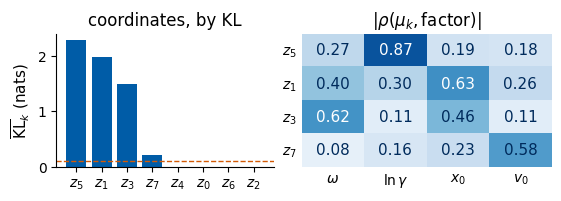

omega-coordinate z_3, gamma-coordinate z_5, x0-coordinate z_1


In [17]:
SHOW_BETA = 4
show_seed = max(SEEDS, key=lambda s: migs[SHOW_BETA, s].mean())
key_show = (SHOW_BETA, show_seed)
act_show = active[key_show][np.argsort(kl_dims[key_show][active[key_show]])[::-1]]   # active, by decreasing KL
print(f"model shown: beta = {SHOW_BETA}, seed = {show_seed} (largest MIG of the three seeds)")
print("|corr|, rows: active coordinates by decreasing KL; columns: omega, ln gamma, x0, v0")
print(np.round(corr[key_show][act_show], 2))

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.9), gridspec_kw=dict(width_ratios=[1, 1.15]))
    order = np.argsort(kl_dims[key_show])[::-1]
    axs[0].bar(np.arange(D_LATENT), kl_dims[key_show][order], color=[UJBlue if k in act_show else UJGray for k in order])
    axs[0].axhline(ACTIVE_NATS, color=DSOrange, lw=1, ls="--")
    axs[0].set_xticks(np.arange(D_LATENT)); axs[0].set_xticklabels([f"$z_{k}$" for k in order])
    axs[0].set_ylabel(r"$\overline{\mathrm{KL}}_k$ (nats)"); axs[0].set_title("coordinates, by KL")
    C_show = corr[key_show][act_show]
    im = axs[1].imshow(C_show, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(C_show):
        axs[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=11, color="white" if v > 0.6 else UJNavy)
    axs[1].set_xticks(range(4)); axs[1].set_xticklabels(FACTOR_NAMES)
    axs[1].set_yticks(range(len(act_show))); axs[1].set_yticklabels([f"$z_{k}$" for k in act_show])
    axs[1].set_title(r"$|\rho(\mu_k,\mathrm{factor})|$")
    axs[1].spines[:].set_visible(False); axs[1].tick_params(length=0)
    save(fig, "gen_traj_corr.png"); plt.show()

k_w = act_show[np.argmax(corr[key_show][act_show, 0])]      # coordinate most correlated with omega
k_g = act_show[np.argmax(corr[key_show][act_show, 1])]      # ... with ln gamma
k_x = act_show[np.argmax(corr[key_show][act_show, 2])]      # ... with x0
print(f"omega-coordinate z_{k_w}, gamma-coordinate z_{k_g}, x0-coordinate z_{k_x}")
nums["show"] = {"beta": SHOW_BETA, "seed": int(show_seed), "active": [int(k) for k in act_show],
                "corr": np.round(corr[key_show][act_show], 3).tolist(), "k_w": int(k_w), "k_g": int(k_g), "k_x": int(k_x)}

The figure shows the model with $\beta=4$ whose MIG is the largest of its three seeds (seed 2). Choosing it requires the true factors, which an experiment without ground truth would not have; the other seeds and values of $\beta$ are summarised in Section 4.3. Its four active coordinates read as follows. $z_5$, the most informative (2.28 nats), follows $\ln\gamma$ with $|\rho|=0.87$ and nothing else above 0.27: it is the **damping coordinate**. $z_1$ follows $x_0$ (0.63) but also $\omega$ (0.40); $z_3$ follows $\omega$ (0.62) and $x_0$ (0.46). $z_7$, the weakest active coordinate (0.22 nats), follows $v_0$ (0.58). Every factor has one coordinate in which it is the largest entry, so the code is roughly one coordinate per factor, but only the damping is clean: frequency and initial position are shared between $z_1$ and $z_3$. Only $z_5$ can be named without hesitation.

### 4.3 Disentangling against β

The figure summarises all twelve models. On the left, for each factor the largest $|\rho|$ over the active coordinates, averaged over the three seeds (band: smallest to largest seed); on the right the gap of the MIG for each factor and their mean, the MIG.

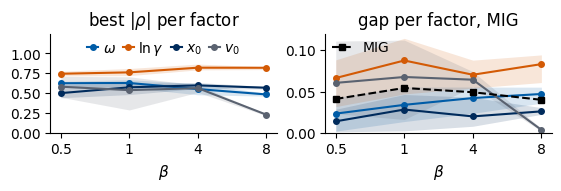

In [18]:
best_corr = {key: corr[key][active[key]].max(0) if len(active[key]) else np.zeros(4) for key in vaes}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.8))
    cols = [UJBlue, DSOrange, UJNavy, UJGray]
    xb = np.arange(len(BETAS))
    for k in range(4):
        m = np.array([[best_corr[b, s][k] for s in SEEDS] for b in BETAS])
        axs[0].plot(xb, m.mean(1), "o-", color=cols[k], label=FACTOR_NAMES[k], ms=4)
        axs[0].fill_between(xb, m.min(1), m.max(1), color=cols[k], alpha=0.15, lw=0)
        g = np.array([[migs[b, s][k] for s in SEEDS] for b in BETAS])
        axs[1].plot(xb, g.mean(1), "o-", color=cols[k], ms=4)
        axs[1].fill_between(xb, g.min(1), g.max(1), color=cols[k], alpha=0.15, lw=0)
    m_all = np.array([[migs[b, s].mean() for s in SEEDS] for b in BETAS])
    axs[1].plot(xb, m_all.mean(1), "s--", color="k", ms=4, label="MIG")
    for a in axs:
        a.set_xticks(xb); a.set_xticklabels([f"{b:g}" for b in BETAS]); a.set_xlabel(r"$\beta$")
    axs[0].set_ylim(0, 1.25); axs[0].set_yticks([0, 0.25, 0.5, 0.75, 1]); axs[0].set_title(r"best $|\rho|$ per factor")
    axs[1].set_title("gap per factor, MIG"); axs[1].set_ylim(0, None)
    axs[0].legend(loc="upper center", ncol=4, handlelength=0.8, columnspacing=0.5, handletextpad=0.3, borderaxespad=0.0)
    axs[1].legend(loc="upper left", handlelength=1.4, borderaxespad=0.1)
    save(fig, "gen_traj_mig.png"); plt.show()
nums["best_corr_mean"] = {str(b): np.mean([best_corr[b, s] for s in SEEDS], 0).round(3).tolist() for b in BETAS}

Over all models the damping is the factor found best: averaged over seeds its largest $|\rho|$ is 0.74 at $\beta=0.5$ and 0.82 at $\beta=4$ and $\beta=8$, with a narrow band over the seeds. The frequency and the initial position stay between 0.48 and 0.63. The initial velocity keeps about 0.55 up to $\beta=4$ and drops to 0.23 at $\beta=8$: it is the factor that the strongest pressure switches off. The MIG, averaged over seeds, is 0.041, 0.054, 0.049 and 0.040 for $\beta=0.5,1,4,8$: no value of $\beta$ gives a disentangled code, and increasing $\beta$ beyond 1 does not help here; it only removes the factor that is least visible in the data. The seed-to-seed spread of the MIG is as large as its change with $\beta$, the observation of Locatello *et al.*

### 4.4 Latent traversals

Correlations are computed from the encoder. A traversal asks the decoder: we take the latent mean $\boldsymbol\mu$ of one test trajectory ($\omega\approx1.5$, $\gamma\approx1$, $x_0\approx1$, $v_0\approx0$), change one active coordinate $z_k$ from $-2.5$ to $2.5$ while keeping the others fixed, and decode. The title of each panel names the factor with the largest $|\rho|$ for that coordinate.

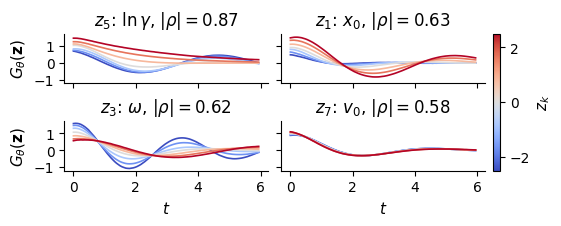

reference trajectory: omega = 1.48, gamma = 1.06, x0 = 1.01, v0 = -0.01


In [19]:
ref = int(np.argmin(((Pte - np.array([1.5, 0.0, 1.0, 0.0])) / Pte.std(0)) ** 2 @ np.ones(4)))
mu_ref = ev[key_show][0][ref]
z_vals = np.linspace(-2.5, 2.5, 7)
trav_coords = list(act_show[:4])
with mpl.rc_context(SLIDE_RC):
    nr = int(np.ceil(len(trav_coords) / 2))
    fig, axs = plt.subplots(nr, 2, figsize=(5.5, 1.0 * nr + 0.15), sharex=True, sharey=True, squeeze=False)
    for a, k in zip(axs.ravel(), trav_coords):
        Z = np.repeat(mu_ref[None], len(z_vals), 0); Z[:, k] = z_vals
        curves = np.asarray(decode(vaes[key_show], jnp.asarray(Z, jnp.float32)))
        for v, cv in zip(z_vals, curves):
            a.plot(t_grid, cv, color=plt.cm.coolwarm((v + 2.5) / 5), lw=1.2)
        f = int(np.argmax(corr[key_show][k]));
        a.set_title(rf"$z_{k}$: {FACTOR_NAMES[f]}, $|\rho|={corr[key_show][k, f]:.2f}$")
    for a in axs.ravel()[len(trav_coords):]:
        a.axis("off")
    for a in axs[-1]: a.set_xlabel("$t$")
    for a in axs[:, 0]: a.set_ylabel(r"$G_\theta(\mathbf{z})$")
    cb = fig.colorbar(plt.cm.ScalarMappable(Normalize(-2.5, 2.5), "coolwarm"), ax=axs, pad=0.02, aspect=20)
    cb.set_label("$z_k$")
    save(fig, "gen_traj_traversal.png"); plt.show()
print("reference trajectory: omega = %.2f, gamma = %.2f, x0 = %.2f, v0 = %.2f" % tuple(Fte[ref]))

The traversals confirm the reading of the correlations and show what the numbers hide. Moving $z_5$ turns a damped oscillation into an overdamped creep: this is the damping. Moving $z_3$ changes the frequency of the decoded oscillation, the position of the first minimum shifts from $t\approx1.8$ to beyond $t=3$, but the starting value $x(0)$ moves as well. Moving $z_1$ changes the initial position and with it the depth of the oscillation, together with its phase. $z_7$ changes the trajectory only slightly, near $t=0$, as befits a coordinate with 0.22 nats.

### 4.5 The frequency and the damping coordinate

A correlation coefficient compresses a cloud of points into one number. The scatter plots show the clouds: the coordinate most correlated with $\omega$ against $\omega$, coloured by $x_0$, and the coordinate most correlated with $\ln\gamma$ against $\ln\gamma$, coloured by the regime. The cell also measures how much of the variance of the $\omega$-coordinate is explained by least-squares fits with $\omega$ alone and with $\omega$ and $x_0$ together, and it computes the correlations separately in the underdamped and the overdamped regime, where Section 1.1 predicts that only $\omega^2/\gamma$ matters.

R^2 of the omega-coordinate z_3 explained by:
  omega                                                   0.385
  omega, x0                                               0.598
  omega, x0, omega*x0                                     0.626
  omega, ln gamma, x0, v0 (all, + squares and products)   0.927
underdamped  (3932 test trajectories): |rho(z_5, ln gamma)| = 0.80, |rho(z_3, omega)| = 0.69, |rho(z_5, ln(omega^2/gamma))| = 0.84, |rho(z_3, ln(omega^2/gamma))| = 0.50
overdamped   (1068 test trajectories): |rho(z_5, ln gamma)| = 0.13, |rho(z_3, omega)| = 0.36, |rho(z_5, ln(omega^2/gamma))| = 0.69, |rho(z_3, ln(omega^2/gamma))| = 0.29


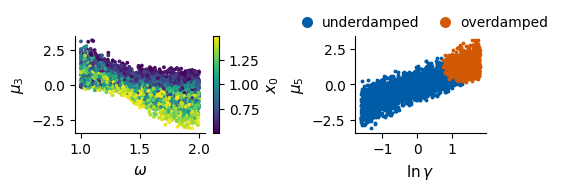

In [20]:
mu_s = ev[key_show][0]
def r2(y, cols):
    """Fraction of the variance of y explained by a least-squares fit with the given columns (and a constant)."""
    A = np.c_[np.ones(len(y)), *cols]
    res = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return 1 - res.var() / y.var()
w_, lg_, x0_ = Pte[:, 0], Pte[:, 1], Pte[:, 2]
fits = {"omega": r2(mu_s[:, k_w], [w_]), "omega, x0": r2(mu_s[:, k_w], [w_, x0_]),
        "omega, x0, omega*x0": r2(mu_s[:, k_w], [w_, x0_, w_ * x0_]),
        "omega, ln gamma, x0, v0 (all, + squares and products)":
            r2(mu_s[:, k_w], [Pte[:, i] * Pte[:, j] for i in range(4) for j in range(i, 4)] + [Pte[:, i] for i in range(4)])}
print(f"R^2 of the omega-coordinate z_{k_w} explained by:")
for k, v in fits.items(): print(f"  {k:55s} {v:.3f}")
for name, m in [("underdamped", ~over_te), ("overdamped", over_te)]:
    print(f"{name:12s} ({m.sum()} test trajectories): |rho(z_{k_g}, ln gamma)| = {abs(np.corrcoef(mu_s[m, k_g], lg_[m])[0, 1]):.2f}, "
          f"|rho(z_{k_w}, omega)| = {abs(np.corrcoef(mu_s[m, k_w], w_[m])[0, 1]):.2f}, "
          f"|rho(z_{k_g}, ln(omega^2/gamma))| = {abs(np.corrcoef(mu_s[m, k_g], 2 * np.log(w_[m]) - lg_[m])[0, 1]):.2f}, "
          f"|rho(z_{k_w}, ln(omega^2/gamma))| = {abs(np.corrcoef(mu_s[m, k_w], 2 * np.log(w_[m]) - lg_[m])[0, 1]):.2f}")
nums["fits_w"] = {k: float(v) for k, v in fits.items()}
nums["regimes"] = {name: {"rho_g": float(abs(np.corrcoef(mu_s[m, k_g], lg_[m])[0, 1])), "rho_w": float(abs(np.corrcoef(mu_s[m, k_w], w_[m])[0, 1])),
                          "rho_g_slow": float(abs(np.corrcoef(mu_s[m, k_g], 2 * np.log(w_[m]) - lg_[m])[0, 1]))}
                   for name, m in [("under", ~over_te), ("over", over_te)]}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.8))
    sc = axs[0].scatter(w_, mu_s[:, k_w], c=x0_, cmap="viridis", s=3, rasterized=True)
    cb = fig.colorbar(sc, ax=axs[0], pad=0.02, aspect=15); cb.set_label("$x_0$")
    axs[0].set_xlabel(r"$\omega$"); axs[0].set_ylabel(rf"$\mu_{k_w}$")
    axs[1].scatter(lg_[~over_te], mu_s[~over_te, k_g], s=3, color=UJBlue, label="underdamped", rasterized=True)
    axs[1].scatter(lg_[over_te], mu_s[over_te, k_g], s=3, color=DSOrange, label="overdamped", rasterized=True)
    axs[1].set_xlabel(r"$\ln\gamma$"); axs[1].set_ylabel(rf"$\mu_{k_g}$")
    axs[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, markerscale=4, handletextpad=0.1,
                  columnspacing=0.8, borderaxespad=0.1)
    save(fig, "gen_traj_scatter.png"); plt.show()

The damping coordinate $\mu_5$ is close to a linear function of $\ln\gamma$ over the whole range. In the overdamped regime (orange) the cloud widens, and the correlations computed separately in the two regimes explain why: among the underdamped trajectories $|\rho(\mu_5,\ln\gamma)|=0.80$, among the overdamped ones only 0.13, while there $\mu_5$ follows $\ln(\omega^2/\gamma)$ with $|\rho|=0.69$. This is the prediction of Section 1.1: deep in the overdamped regime a trajectory is a slow decay with rate $\approx\omega^2/\gamma$, and the damping coordinate follows that combination ($|\rho|=0.69$). In the underdamped regime the correlation with $\ln(\omega^2/\gamma)$ is also high, 0.84, because $\omega$ varies only by a factor of 2 while $\gamma$ varies by a factor of 30, so that $\ln(\omega^2/\gamma)$ is dominated by $\ln\gamma$.

The frequency coordinate $\mu_3$ decreases with $\omega$, but the colours show that the slope depends on $x_0$: for small initial positions (dark) $\mu_3$ hardly changes with $\omega$, for large ones (yellow) it changes strongly. A least-squares fit with $\omega$ alone explains $R^2=0.385$ of its variance, with $\omega$ and $x_0$ 0.598, with the product $\omega x_0$ in addition 0.626, and with all factors, their squares and products 0.927. The coordinate is therefore a nonlinear function of the factors, dominated by $\omega$ and $x_0$ together. Physically this is natural: the encoder can measure the frequency only as precisely as the oscillation is visible, and the amplitude of the oscillation is set by $x_0$. A code that stores $\omega$ to a precision proportional to its visibility uses a scale that depends on $x_0$.

### 4.6 Sensitivity of a trajectory to the parameters

The network can only separate what the data separate. How strongly does a trajectory respond to each factor, and do two factors change it in different ways? For the Gaussian likelihood with mean $\langle\mathbf x\rangle(\mathbf p)$ and parameters $\mathbf p=(\omega,\ln\gamma,x_0,v_0)$, both questions are answered by the Fisher information matrix
$$F_{ab}=\frac{1}{\sigma_x^2}\sum_{i=1}^T\frac{\partial\langle x(t_i)\rangle}{\partial p_a}\,\frac{\partial\langle x(t_i)\rangle}{\partial p_b}.$$
Its diagonal says how many $\sigma_x$ the trajectory moves when one parameter changes: we report the visibility $\sqrt{F_{aa}}\,\mathrm{std}(p_a)$, the change of the whole trajectory, in units of $\sigma_x$, for a change of $p_a$ by one standard deviation of its distribution in the data. The normalised off-diagonal element $F_{ab}/\sqrt{F_{aa}F_{bb}}$ is the cosine of the angle between the two sensitivity vectors $\partial\langle\mathbf x\rangle/\partial p_a$ and $\partial\langle\mathbf x\rangle/\partial p_b$. If it is close to $\pm1$, a small change of $p_a$ can be compensated by a change of $p_b$: the data hardly distinguish the two directions, and a network has no reason to put them into different coordinates. The derivatives of the exact mean trajectory are obtained with `jax.jacfwd`, at 2000 test parameter points; we report medians.

In [21]:
def sensitivity_matrix(mean_fn, P, t):
    """Fisher information F_ab = (1/sigma_x^2) sum_i d<x(t_i)>/dp_a d<x(t_i)>/dp_b at every parameter point P (n, K)."""
    J = jax.vmap(jax.jacfwd(mean_fn), in_axes=(0, None))(jnp.asarray(P, jnp.float32), jnp.asarray(t))   # (n, T, K)
    return np.asarray(jnp.einsum("nta,ntb->nab", J, J)) / SIGMA_X**2

osc_mean = lambda p, t: mean_trajectory(p[0], jnp.exp(p[1]), p[2], p[3], t)     # p = (omega, ln gamma, x0, v0)
F_fish = sensitivity_matrix(osc_mean, Pte[:2000], t_grid)
diag = np.sqrt(np.einsum("naa->na", F_fish))
cosines = np.median(np.abs(F_fish / (diag[:, :, None] * diag[:, None, :])), 0)
visibility = np.median(diag, 0) * Pte.std(0)          # change of the trajectory, in units of sigma_x, for a 1-std change
print("median |cos| between the sensitivity vectors d<x>/dp (omega, ln gamma, x0, v0):")
print(np.round(cosines, 2))
print("median visibility  sqrt(F_aa) * std(p_a)  (omega, ln gamma, x0, v0):", np.round(visibility, 1))
nums["fisher_cos"] = np.round(cosines, 3).tolist(); nums["visibility"] = np.round(visibility, 2).tolist()

median |cos| between the sensitivity vectors d<x>/dp (omega, ln gamma, x0, v0):
[[1.   0.69 0.24 0.79]
 [0.69 1.   0.48 0.46]
 [0.24 0.48 1.   0.59]
 [0.79 0.46 0.59 1.  ]]
median visibility  sqrt(F_aa) * std(p_a)  (omega, ln gamma, x0, v0): [16.7 23.3 11.9  5.4]


The visibilities order the factors: a change of $\ln\gamma$ by one standard deviation moves the trajectory by 23.3 $\sigma_x$, of $\omega$ by 16.7, of $x_0$ by 11.9, and of $v_0$ by only 5.4. The factor that the network drops first at large $\beta$, $v_0$, is the least visible one: the KL price of storing it exceeds the reconstruction gain. The cosines show which directions the data confuse. The largest one, 0.79, belongs to $\omega$ and $v_0$: within the window, a faster oscillation and a negative initial velocity both bring the particle down earlier, and the two changes look alike. $\omega$ and $\ln\gamma$ follow with 0.69, since stronger friction also lowers the damped frequency $\omega_d=\sqrt{\omega^2-\gamma^2/4}$ and shifts the zero crossings. $\omega$ and $x_0$ have the smallest cosine, 0.24, so the local, linear picture does not explain why they share coordinates; the mixing is nonlinear, the product structure seen in Section 4.5, because the sensitivity to $\omega$ is itself proportional to the amplitude.

This also explains the choice of the parameter ranges. With many oscillation periods in the window, $\partial\langle x(t)\rangle/\partial\omega\propto t\,\sin(\omega_dt)$ grows with time and oscillates; the trajectories for neighbouring $\omega$ separate quickly, the map from $\omega$ to the trajectory folds on itself, and a Gaussian code with a smooth decoder cannot follow it. With $x_0$ of both signs, the trajectory of $(\omega,\gamma,x_0,v_0)$ and that of $(\omega,\gamma,-x_0,-v_0)$ differ only by a sign, and the code must fold again.

In summary, the $\beta$-VAE finds the number of independent factors and, robustly, the damping; it finds the frequency and the initial conditions only as mixtures. The most visible and least confusable parameter is the one that ends up in its own coordinate.

<hr/>
## 5. Question-and-answer networks

### 5.1 SciNet of Iten et al.

Iten, Metger, Wilming, del Rio and Renner [Phys. Rev. Lett. **124**, 010508 (2020)] proposed a network modelled on how a physicist works: observations are compressed into a few parameters, and the parameters, not the raw data, are used to answer questions about the system. Their network, SciNet, has three parts (their Fig. 1). An encoder, a feed-forward network, maps an observation $o$ to a small latent representation; a question $q$, encoded as real numbers, is appended to the latent values; a decoder, again feed-forward, maps (representation, question) to an answer $a$. Training uses triples $(o,q,a_{\rm corr}(o,q))$. Unlike an autoencoder, the latent representation need not describe the observation completely, only what is needed to answer the questions. To make the latent neurons statistically independent, they use the $\beta$-VAE cost: the encoder outputs means and standard deviations of independent Gaussians, and with a Gaussian decoder of fixed variance the cost becomes (their Eq. (D1), Supplemental Material)
$$\begin{aligned}
C_\beta&=\lVert\hat a-a\rVert_2^2-\frac\beta2\sum_i\big(\log\sigma_i^2-\mu_i^2-\sigma_i^2\big)+\text{const}\\
&=\lVert\hat a-a\rVert_2^2+\beta\,\mathrm{KL}+\text{const},
\end{aligned}$$
the same KL term as ours, with the reconstruction measured on the answer instead of on the input.

Their first example (Box 1 and Sec. E1 of the Supplemental Material; arXiv:1807.10300) is a damped pendulum, $m\ddot x=-\kappa x-b\dot x$, without noise. The mass $m=1\,$kg, the amplitude $A_0=1\,$m and the phase $\delta_0=0$ are fixed, so that $x(t)=A_0e^{-bt/(2m)}\cos(\omega t+\delta_0)$ with $\omega=\sqrt{\kappa/m}\sqrt{1-b^2/(4m\kappa)}$; the spring constant $\kappa\in[5,10]\,$kg/s$^2$ and the damping factor $b\in[0.5,1]\,$kg/s vary between samples. The observation is the position at 50 equally spaced times in $[0,5]\,$s, the question a prediction time $t_{\rm pred}\in[0,10]\,$s, the answer $x(t_{\rm pred})$. The encoder has hidden layers of 500 and 100 neurons, the decoder two layers of 100, with exponential linear units (ELU, $u$ for $u>0$ and $e^u-1$ otherwise), and three latent neurons (their Table I); training used 95 000 samples, batch size 512, learning rate $10^{-3}$, $\beta=10^{-3}$ and 1000 epochs (their Table II). They report predictions with a root-mean-square error below 2% of the amplitude, and that the network stores $\kappa$ and $b$ in two latent neurons, the first depending nearly linearly on $b$ and almost not on $\kappa$, the second only on $\kappa$, while the third neuron carries no information (their Fig. 6; the main text speaks of "frequency and damping factor").

Compared with our $\beta$-VAE, three things differ. The decoder answers one question at a time instead of reproducing the whole input, and the questions reach beyond the observed window, so the code must allow extrapolation. The data contain no noise and no nuisance factors: with fixed amplitude and phase, $\kappa$ and $b$ are the only things that vary. And $\beta=10^{-3}$ is small in their units: the KL term only breaks the rotational symmetry of the latent space, it hardly limits the information.

### 5.2 Data in the setting of the paper

We generate the pendulum data of the paper on the grid $t=0,0.1,\dots,10$: the observation is the first 50 points, $t\in[0,4.9]$ (the paper uses 50 points on $[0,5]$), and the questions are the 101 grid times. The initial condition $x(0)=1$, $\dot x(0)=-b/2$ reproduces $e^{-bt/2}\cos\omega t$; the cell checks this against the closed form. To see what noise and nuisance factors do, we build two more versions of the same data: with the random force of strength $D=0.002$ (Euler–Maruyama, $\Delta t=0.01$), and with noise and random initial conditions $x_0\in[0.5,1.5]$, $v_0\in[-0.5,0.5]$ as in Section 2. Each version has 20 000 training and 5000 test trajectories. The cell also repeats the sensitivity analysis of Section 4.6 for $(\kappa,b)$ on the observation window.

In [22]:
KAPPA_RANGE, B_RANGE = (5.0, 10.0), (0.5, 1.0)       # spring constant and damping factor of Iten et al. (m = 1)
t_q = 0.1 * np.arange(101)                             # question times 0, 0.1, ..., 10
N_OBS = 50                                             # observation: x at t = 0, 0.1, ..., 4.9

def make_paper_data(n, seed, noise=False, random_ic=False):
    """Trajectories on t_q (n, 101) and factors (kappa, b, x0, v0). Without random_ic: A0 = 1, delta0 = 0,
    i.e. x(0) = 1, x'(0) = -b/2, so that the noise-free solution is exp(-b t / 2) cos(omega t)."""
    rng = np.random.default_rng(seed)
    kap, b = rng.uniform(*KAPPA_RANGE, n), rng.uniform(*B_RANGE, n)
    x0, v0 = (rng.uniform(*X0_RANGE, n), rng.uniform(-V0_MAX, V0_MAX, n)) if random_ic else (np.ones(n), -b / 2)
    args = [jnp.asarray(a, jnp.float32) for a in (np.sqrt(kap), b, x0, v0)]
    if noise:
        X, _ = simulate(*args, jax.random.key(seed), n_sub=10, n_rec=101)
    else:
        X = mean_trajectories(*args, jnp.asarray(t_q))
    return np.asarray(X, np.float32), np.stack([kap, b, x0, v0], 1)

# the closed form of the paper, x(t) = exp(-b t/2) cos(omega t) with omega = sqrt(kappa - b^2/4), is reproduced
Xp, Fp = make_paper_data(5, 0)
om_p = np.sqrt(Fp[:, 0] - Fp[:, 1]**2 / 4)
print("max |x - exp(-bt/2) cos(omega t)| =", np.abs(Xp - np.exp(-Fp[:, 1:2] * t_q / 2) * np.cos(om_p[:, None] * t_q)).max())

SETUPS = {"noise-free, fixed A0 and phase (paper)": dict(noise=False, random_ic=False),
          "with noise": dict(noise=True, random_ic=False),
          "with noise and random x0, v0": dict(noise=True, random_ic=True)}
paper_sets = {name: (make_paper_data(20_000, 21, **kw), make_paper_data(5_000, 22, **kw)) for name, kw in SETUPS.items()}

# the sensitivity (Fisher) analysis of Section 4.6 for the parameters (kappa, b) on the observation window
paper_mean = lambda p, t: mean_trajectory(jnp.sqrt(p[0]), p[1], 1.0, -p[1] / 2, t)
Fp_fish = sensitivity_matrix(paper_mean, paper_sets["noise-free, fixed A0 and phase (paper)"][1][1][:2000, :2], t_q[:N_OBS])
dp = np.sqrt(np.einsum("naa->na", Fp_fish))
print(f"median |cos(kappa, b)| = {np.median(np.abs(Fp_fish[:, 0, 1]) / (dp[:, 0] * dp[:, 1])):.2f}; "
      f"visibility (kappa, b) = {np.round(np.median(dp, 0) * np.array([5, 0.5]) / np.sqrt(12), 1)}")

max |x - exp(-bt/2) cos(omega t)| = 2.4576880644500143e-07


median |cos(kappa, b)| = 0.14; visibility (kappa, b) = [11.2  3. ]


The closed form of the paper is reproduced to the precision of single-precision arithmetic. The sensitivity analysis gives a median $|\cos|$ of 0.14 between the directions of $\kappa$ and $b$ on the observation window, much smaller than the cosines between our factors in Section 4.6, and visibilities of 11.2 and 3.0 $\sigma_x$ for one standard deviation of $\kappa$ and of $b$: in the setting of the paper the two parameters change the trajectory in nearly orthogonal ways.

### 5.3 Network and cost

Our implementation follows Tables I and II of the paper for the layer sizes, the activation, the batch size, the learning rate and $\beta=10^{-3}$. Each observation is paired with 8 random question times per training step, so one minibatch contains 4096 (observation, question, answer) triples that share 512 samples of $\mathbf z$; the cost is the mean of $(\hat x-x)^2$ over the triples plus $\beta$ times the KL. We train for 100 epochs on 20 000 observations instead of 1000 epochs on 95 000: about 4000 gradient steps instead of about 186 000, a difference to keep in mind when comparing results. For the setting of the paper we therefore also train SciNet for 1000 epochs, about 39 000 steps. With random initial conditions the representation needs two more numbers, so that version gets five latent neurons instead of three. For comparison, each data version also trains our $\beta$-VAE ($\beta=4$, $\sigma_x=0.1$, same latent size, 60 epochs) on the 50 observed points. The drawing shows both networks in the same style: the $\beta$-VAE reconstructs the observation, SciNet receives the question $t$ next to $\mathbf z$ and returns one number.

In [23]:
class SciNet(nnx.Module):
    """Question-and-answer network in the style of Iten et al.: ELU activations.
    encoder: observation o (B, 50) -> 500 -> 100 -> mu (B, d), logvar (B, d)
    decoder: [z, t] (B, Q, d + 1)  -> 100 -> 100 -> answer x(t) (B, Q)"""
    def __init__(self, n_obs=N_OBS, d=3, *, rngs):
        self.e1, self.e2 = nnx.Linear(n_obs, 500, rngs=rngs), nnx.Linear(500, 100, rngs=rngs)
        self.mu, self.logvar = nnx.Linear(100, d, rngs=rngs), nnx.Linear(100, d, rngs=rngs)
        self.d1, self.d2, self.d3 = nnx.Linear(d + 1, 100, rngs=rngs), nnx.Linear(100, 100, rngs=rngs), nnx.Linear(100, 1, rngs=rngs)

    def encode(self, o):
        h = nnx.elu(self.e2(nnx.elu(self.e1(o))))
        return self.mu(h), self.logvar(h)

    def answer(self, z, q):
        """z (B, d), question times q (B, Q) -> predicted positions (B, Q)."""
        zq = jnp.concatenate([jnp.repeat(z[:, None, :], q.shape[1], 1), q[..., None]], -1)
        return self.d3(nnx.elu(self.d2(nnx.elu(self.d1(zq)))))[..., 0]

def scinet_loss(model, batch, key, beta=1e-3, n_q=8):
    """Cost of Iten et al. per (observation, question, answer) triple: (x_hat - x)^2 + beta KL;
    here n_q random questions per observation share one sample z."""
    o, a = batch                                   # observation (B, 50), answers on all question times (B, 101)
    k1, k2 = jax.random.split(key)
    mu, logvar = model.encode(o)
    z = reparametrise(mu, logvar, k1)
    idx = jax.random.randint(k2, (o.shape[0], n_q), 0, a.shape[1])
    pred = model.answer(z, jnp.asarray(t_q, jnp.float32)[idx])
    rec = ((pred - jnp.take_along_axis(a, idx, 1)) ** 2).mean()
    kl = kl_per_dim(mu, logvar).sum(-1).mean()
    return rec + beta * kl, {"loss": rec + beta * kl, "rec": rec, "kl": kl}

_s = SciNet(rngs=nnx.Rngs(0))
print("SciNet parameters:", sum(p.size for p in jax.tree.leaves(nnx.state(_s, nnx.Param))))

SciNet parameters: 86907


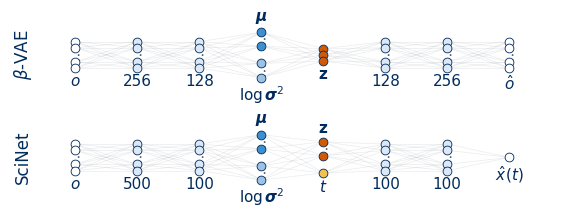

In [24]:
def scinet_columns(n_obs=N_OBS, d=3):
    """Columns of the question-and-answer network: o -> 500 -> 100 -> (mu, log sigma^2) -> [z, t] -> 100 -> 100 -> x(t)."""
    return [[dict(n=n_obs, color="white", label=r"$o$")], [dict(n=500, color=UJLight, label="500")],
            [dict(n=100, color=UJLight, label="100")],
            [dict(n=d, color=UJSky, label=r"$\boldsymbol{\mu}$", show=2), dict(n=d, color="#9CC3E6", label=r"$\log\boldsymbol{\sigma}^2$", show=2)],
            [dict(n=d, color=DSOrange, label=r"$\mathbf{z}$", show=2), dict(n=1, color="#F2C14E", label="$t$")],
            [dict(n=100, color=UJLight, label="100")], [dict(n=100, color=UJLight, label="100")],
            [dict(n=1, color="white", label=r"$\hat x(t)$")]]

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.05), layout="none")
    axs = fig.subplots(2, 1)
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0)
    draw_network(axs[0], vae_columns(N_OBS, (256, 128), 3, in_label=r"$o$", out_label=r"$\hat o$"), x_gap=0.95, max_nodes=4,
                 y_gap=0.2, node_r=0.085)
    axs[0].text(-0.8, 0, r"$\beta$-VAE", rotation=90, ha="center", va="center", fontsize=12, color=UJNavy)
    draw_network(axs[1], scinet_columns(), x_gap=0.95, max_nodes=4, y_gap=0.2, node_r=0.085)
    axs[1].text(-0.8, 0, "SciNet", rotation=90, ha="center", va="center", fontsize=12, color=UJNavy)
    for a in axs: a.set_xlim(-1.0, 7.3); a.set_ylim(-1.4, 1.25)
    save(fig, "gen_traj_scinet.png"); plt.show()

### 5.4 Training and probing

Both networks are probed in the same way as in Section 4: KL per latent neuron, active neurons, $|\rho|$ with $\kappa$ and $b$ on the test set. For each parameter we print the best and the second-best $|\rho|$ over the active neurons; a large best value and a small second value mean that one neuron, and only one, follows the parameter.

In [25]:
EPOCHS_QA = 100
probe = {}
t0 = time.time()
for j, (name, ((Xa, Fa), (Xb, Fb))) in enumerate(paper_sets.items()):
    d_lat = 5 if SETUPS[name]["random_ic"] else 3
    sn, _ = train(lambda s: SciNet(d=d_lat, rngs=nnx.Rngs(s)), scinet_loss, (Xa[:, :N_OBS], Xa), EPOCHS_QA, 0,
                  name=f"lab028_scinet_setup{j}", batch_size=512)
    bv, _ = train(lambda s: TrajVAE(N_OBS, d_lat, rngs=nnx.Rngs(s)), partial(beta_vae_loss, beta=4), (Xa[:, :N_OBS],), 60, 0,
                  name=f"lab028_paper_bvae_setup{j}")
    P_b = np.c_[Fb[:, :2], Fb[:, 2:]] if SETUPS[name]["random_ic"] else Fb[:, :2]
    nets = [("SciNet", sn), ("beta-VAE", bv)]
    if j == 0:                                     # the setting of the paper, also trained for 1000 epochs as there
        sn_long, _ = train(lambda s: SciNet(d=d_lat, rngs=nnx.Rngs(s)), scinet_loss, (Xa[:, :N_OBS], Xa), 1000, 0,
                           name="lab028_scinet_setup0_1000ep", batch_size=512, log_every=250)
        nets.append(("SciNet, 1000 epochs", sn_long))
    for net_name, net in nets:
        mu, lv = (np.asarray(a) for a in encode(net, jnp.asarray(Xb[:, :N_OBS])))
        kl_n = np.asarray(kl_per_dim(mu, lv)).mean(0)
        act_n = np.flatnonzero(kl_n > ACTIVE_NATS)
        probe[name, net_name] = dict(kl=kl_n, active=act_n, corr=abs_corr(mu, P_b), mu=mu)
    for net_name, net in nets:
        if net_name.startswith("SciNet"):
            pred = np.asarray(nnx.jit(lambda m, o, q: m.answer(m.encode(o)[0], q))(net, jnp.asarray(Xb[:, :N_OBS]),
                                      jnp.tile(jnp.asarray(t_q, jnp.float32), (len(Xb), 1))))
            probe[name, net_name]["rmse"] = float(np.sqrt(((pred - Xb) ** 2).mean()))
            probe[name, net_name]["pred"] = pred
print(f"question-and-answer networks and beta-VAEs ready in {time.time() - t0:.0f} s")

print("setup | network | KL per latent neuron | |rho| with kappa (best, second) | |rho| with b (best, second)")
rows_qa = {}
for (name, net_name), p in probe.items():
    c = p["corr"][p["active"]] if len(p["active"]) else np.zeros((1, p["corr"].shape[1]))
    srt = np.sort(c, 0)[::-1]
    second = srt[1] if len(srt) > 1 else np.zeros(c.shape[1])
    rows_qa[name, net_name] = dict(best=srt[0].tolist(), second=second.tolist(), n_active=int(len(p["active"])))
    print(f"{name:38s} | {net_name:19s} | {np.round(np.sort(p['kl'])[::-1], 2)} | {srt[0, 0]:.2f}, {second[0]:.2f} | {srt[0, 1]:.2f}, {second[1]:.2f}")
print("rms prediction error of SciNet over t in [0, 10]:", {f"{n} | {net}": round(p["rmse"], 4) for (n, net), p in probe.items() if "rmse" in p})
nums["qa"] = {f"{i}_{net}": rows_qa[n, net] for i, n in enumerate(SETUPS) for net in ("SciNet", "beta-VAE")}
nums["qa_long"] = rows_qa[list(SETUPS)[0], "SciNet, 1000 epochs"]
nums["qa_rmse"] = [probe[n, "SciNet"]["rmse"] for n in SETUPS]
nums["qa_rmse_long"] = probe[list(SETUPS)[0], "SciNet, 1000 epochs"]["rmse"]

question-and-answer networks and beta-VAEs ready in 18 s
setup | network | KL per latent neuron | |rho| with kappa (best, second) | |rho| with b (best, second)
noise-free, fixed A0 and phase (paper) | SciNet              | [3.64 1.23 0.03] | 0.96, 0.85 | 0.50, 0.21
noise-free, fixed A0 and phase (paper) | beta-VAE            | [1.69 0.39 0.  ] | 0.99, 0.01 | 0.97, 0.08
noise-free, fixed A0 and phase (paper) | SciNet, 1000 epochs | [1.7  0.44 0.  ] | 1.00, 0.05 | 0.98, 0.06
with noise                             | SciNet              | [3.99 0.9  0.03] | 0.98, 0.84 | 0.49, 0.10
with noise                             | beta-VAE            | [1.78 0.5  0.  ] | 0.98, 0.03 | 0.96, 0.08
with noise and random x0, v0           | SciNet              | [3.64 1.33 0.04 0.04 0.02] | 0.91, 0.43 | 0.30, 0.02
with noise and random x0, v0           | beta-VAE            | [1.94 1.34 0.19 0.   0.  ] | 0.90, 0.06 | 0.79, 0.26
rms prediction error of SciNet over t in [0, 10]: {'noise-free, fixed A0 and p

In the setting of the paper and after 100 epochs, SciNet uses two latent neurons (3.64 and 1.23 nats) and switches the third one off (0.03 nats), as reported by Iten *et al.* The two active neurons, however, both follow $\kappa$ ($|\rho|=0.96$ and $0.85$), and $b$ reaches only $|\rho|=0.50$: the representation is good enough for predictions (root-mean-square error 0.0518 over $t\in[0,10]$, 5% of the amplitude) but not disentangled. Trained for 1000 epochs, as in the paper, the same network separates the two parameters: one neuron follows $\kappa$ with $|\rho|=1.00$, the other $b$ with $0.98$, the second-best correlations are only $0.05$ and $0.06$, the third neuron carries no information (0.00 nats), and the prediction error drops to 0.0275, 2.8% of the amplitude (the paper reports below 2% after 1000 epochs on 95 000 samples). This reproduces their finding of one neuron per parameter, with a prediction error still somewhat above theirs.

The $\beta$-VAE with $\beta=4$ reaches the same separation after 60 epochs ($|\rho|=0.99$ for $\kappa$ and $0.97$ for $b$, second-best $0.01$ and $0.08$). Its KL term is far more expensive: per observed position, SciNet weighs a squared error of one with 1 and the KL with $\beta=10^{-3}$, while our $\beta$-VAE weighs it with $1/(2\sigma_x^2)=50$ and the KL with $\beta=4$, a ratio of 0.08, eighty times larger. The stronger pull towards the factorised prior aligns the code with independent directions much sooner; SciNet's small $\beta$ breaks the rotational symmetry of the latent space only slowly.

The random force of strength $D=0.002$ changes nothing essential for either network at 100 epochs: SciNet again has two neurons following $\kappa$ ($0.98$ and $0.84$) and $b$ at $0.49$, the $\beta$-VAE separates $\kappa$ ($0.98$) and $b$ ($0.96$). Random initial conditions change more. SciNet keeps only two of its five neurons active and stores $\kappa$ ($0.91$) and $x_0$ ($0.86$), but not $b$ ($0.30$) or $v_0$: for answering questions over $[0,10]$, the frequency and the starting point matter most, and at 100 epochs the network has not yet found room for the damping. The $\beta$-VAE keeps three active coordinates, for $\kappa$ ($0.90$), $b$ ($0.79$, with $0.26$ in a second coordinate) and $x_0$ ($0.75$), and drops $v_0$ ($0.25$), the least visible factor, as in Section 4.

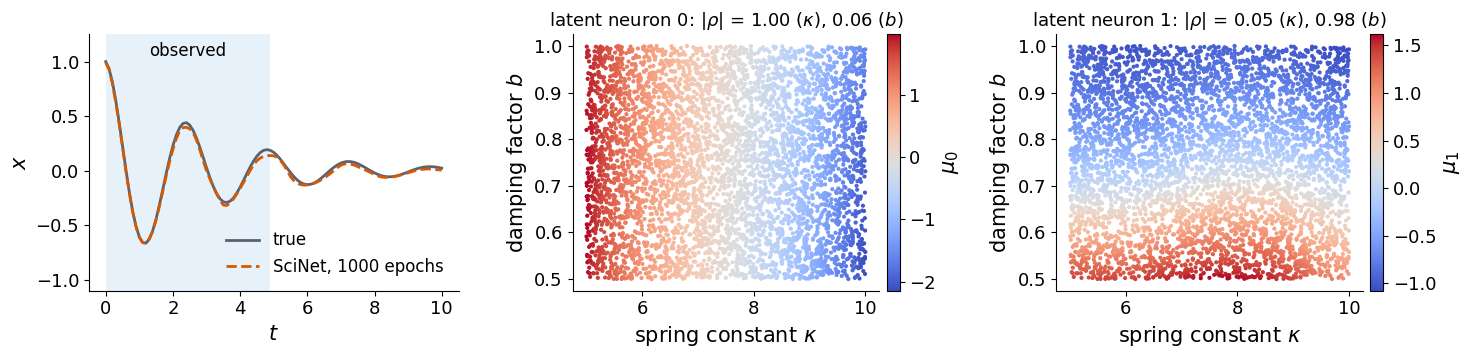

In [26]:
name0 = list(SETUPS)[0]
(_, _), (Xb0, Fb0) = paper_sets[name0]
p0 = probe[name0, "SciNet, 1000 epochs"]
act0 = p0["active"][np.argsort(p0["kl"][p0["active"]])[::-1]]
fig, axs = plt.subplots(1, 1 + len(act0), figsize=(5 * (1 + len(act0)), 3.8))
i0 = 0
axs[0].plot(t_q, Xb0[i0], color=UJGray, label="true"); axs[0].plot(t_q, p0["pred"][i0], "--", color=DSOrange, label="SciNet, 1000 epochs")
axs[0].axvspan(0, t_q[N_OBS - 1], color=UJSky, alpha=0.12, lw=0); axs[0].text(2.45, 1.05, "observed", ha="center", fontsize=12)
axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$x$"); axs[0].legend(loc="lower right"); axs[0].set_ylim(-1.1, 1.25)
for a, kz in zip(axs[1:], act0):
    sc = a.scatter(Fb0[:, 0], Fb0[:, 1], c=p0["mu"][:, kz], cmap="coolwarm", s=4)
    fig.colorbar(sc, ax=a, pad=0.02).set_label(rf"$\mu_{kz}$")
    a.set_xlabel(r"spring constant $\kappa$"); a.set_ylabel("damping factor $b$")
    a.set_title(rf"latent neuron {kz}: $|\rho|$ = {p0['corr'][kz, 0]:.2f} ($\kappa$), {p0['corr'][kz, 1]:.2f} ($b$)", fontsize=13)
plt.tight_layout(); plt.show()

The figure shows the SciNet trained for 1000 epochs in the setting of the paper. On the left it predicts a test trajectory over $[0,10]$ from the observed first half (shaded). In the middle and on the right every test observation is placed at its true $(\kappa,b)$ and coloured by the mean of one latent neuron: the colour of neuron 0 changes only along $\kappa$, that of neuron 1 only along $b$, the analogue of Fig. 6b of the paper. Both networks, the question-and-answer network and the $\beta$-VAE, thus find the same physical parameters when the data contain only these two, the question-and-answer network after much longer training. With nuisance factors and short training both store the most visible parameters first.

<hr/>
## 6. Two coupled oscillators

### 6.1 Equations of motion and normal modes

Two equal masses $m$ are each attached to a wall by a spring $k$ and to each other by a coupling spring $k_c$; both move in the same fluid, with friction rate $\gamma$, and each is hit by its own random force:
$$\begin{aligned}
m\ddot x_1&=-kx_1-k_c(x_1-x_2)-m\gamma\dot x_1+m\sqrt{2D}\,\xi_1(t),\\
m\ddot x_2&=-kx_2-k_c(x_2-x_1)-m\gamma\dot x_2+m\sqrt{2D}\,\xi_2(t),
\end{aligned}$$
with $\xi_1,\xi_2$ independent white noises. In matrix form $m\ddot{\mathbf x}=-K\mathbf x-m\gamma\dot{\mathbf x}+\dots$ with the stiffness matrix $K=\begin{pmatrix}k+k_c&-k_c\\-k_c&k+k_c\end{pmatrix}$. Its eigenvectors are the **normal modes**: the in-phase motion $(1,1)$, in which the coupling spring is never stretched, with $\omega_1^2=k/m$, and the anti-phase motion $(1,-1)$, in which the coupling spring is stretched twice as much as each mass moves, with $\omega_2^2=(k+2k_c)/m$. SymPy finds them, and `numpy.linalg.eigvalsh` confirms them for random spring constants.

In [27]:
k, kc, m_ = sp.symbols("k k_c m", positive=True)
K = sp.Matrix([[k + kc, -kc], [-kc, k + kc]])            # m x'' = -K x - m gamma x' + noise
for val, mult, vecs in K.eigenvects():
    print(f"eigenvalue {sp.simplify(val)}:  omega^2 = {sp.simplify(val / m_)},  mode {list(vecs[0])}")

# numerical check for a few random spring constants (m = 1)
rng = np.random.default_rng(0)
for _ in range(3):
    kv, kcv = rng.uniform(1, 4), rng.uniform(0.2, 2)
    ev_num = np.linalg.eigvalsh(np.array([[kv + kcv, -kcv], [-kcv, kv + kcv]]))
    print(f"k = {kv:.3f}, k_c = {kcv:.3f}: eigvalsh -> omega = {np.sqrt(ev_num).round(6)},"
          f"  formulas -> {np.round([np.sqrt(kv), np.sqrt(kv + 2 * kcv)], 6)}")

eigenvalue k:  omega^2 = k/m,  mode [1, 1]
eigenvalue k + 2*k_c:  omega^2 = (k + 2*k_c)/m,  mode [-1, 1]
k = 2.911, k_c = 0.686: eigvalsh -> omega = [1.706132 2.069328],  formulas -> [1.706132 2.069328]
k = 1.123, k_c = 0.230: eigvalsh -> omega = [1.059679 1.257943],  formulas -> [1.059679 1.257943]
k = 3.440, k_c = 1.843: eigvalsh -> omega = [1.854673 2.669406],  formulas -> [1.854673 2.669406]


In the mode coordinates $q_\pm=(x_1\pm x_2)/\sqrt2$ the two equations separate:
$$\begin{aligned}
\ddot q_+&=-\omega_1^2q_+-\gamma\dot q_++\sqrt{2D}\,\xi_+,\\
\ddot q_-&=-\omega_2^2q_--\gamma\dot q_-+\sqrt{2D}\,\xi_-,\qquad \xi_\pm=\frac{\xi_1\pm\xi_2}{\sqrt2}.
\end{aligned}$$
The friction is the same for both masses, so it does not couple the modes, and $\xi_\pm$ are again independent white noises of unit strength, because $\langle\xi_+\xi_-\rangle=\frac12(\langle\xi_1^2\rangle-\langle\xi_2^2\rangle)=0$. The two masses are therefore two independent noisy oscillators of Section 1, seen through a rotation of $45^\circ$. A trajectory depends on the springs **only through $\omega_1$ and $\omega_2$**. Below, the Euler–Maruyama integrator of the two masses is run without noise from $x_1=1$, $x_2=0.2$ at rest, and $q_\pm$ are compared with the exact damped oscillators at $\omega_1$ and $\omega_2$ (with $m=1$).

In [28]:
def simulate_two(k, kc, gamma, x10, x20, v10, v20, key, D=D_NOISE, dt=DT, n_sub=N_SUB, n_rec=T_POINTS):
    """Euler-Maruyama for N pairs of coupled masses (m = 1); all parameters (N,). Returns positions (N, 2, n_rec)."""
    def em_step(state, kk):
        x1, x2, v1, v2 = state
        e1, e2 = jax.random.normal(kk, (2,) + x1.shape)          # independent noises on the two masses
        a1 = -k * x1 - kc * (x1 - x2) - gamma * v1
        a2 = -k * x2 - kc * (x2 - x1) - gamma * v2
        s = jnp.sqrt(2 * D * dt)
        return (x1 + v1 * dt, x2 + v2 * dt, v1 + a1 * dt + s * e1, v2 + a2 * dt + s * e2), None
    def record(state, kk):
        state, _ = jax.lax.scan(em_step, state, jax.random.split(kk, n_sub))
        return state, state[:2]
    _, (x1s, x2s) = jax.lax.scan(record, (x10, x20, v10, v20), jax.random.split(key, n_rec - 1))
    x1 = jnp.concatenate([x10[None], x1s]).T; x2 = jnp.concatenate([x20[None], x2s]).T
    return jnp.stack([x1, x2], 1)
simulate_two = jax.jit(simulate_two, static_argnames=("n_sub", "n_rec"))

# check without noise: the mode coordinates q_+ = (x1 + x2)/sqrt2 and q_- = (x1 - x2)/sqrt2 are single damped oscillators
kv, kcv, gv = 2.0, 1.0, 0.3
one = jnp.ones(1)
X2 = np.asarray(simulate_two(kv * one, kcv * one, gv * one, 1.0 * one, 0.2 * one, 0 * one, 0 * one, jax.random.key(0), D=0.0,
                             n_sub=1, n_rec=601))[0]
t_fine = DT * np.arange(601)
q_plus, q_minus = (X2[0] + X2[1]) / np.sqrt(2), (X2[0] - X2[1]) / np.sqrt(2)
for name, q, om in [("q+", q_plus, np.sqrt(kv)), ("q-", q_minus, np.sqrt(kv + 2 * kcv))]:
    ex = np.asarray(mean_trajectory(om, gv, q[0], 0.0, jnp.asarray(t_fine)))      # both masses start at rest
    print(f"{name}: max |Euler (dt = {DT}) - damped oscillator with omega = {om:.4f}| = {np.abs(q - ex).max():.4f}")

q+: max |Euler (dt = 0.01) - damped oscillator with omega = 1.4142| = 0.0199
q-: max |Euler (dt = 0.01) - damped oscillator with omega = 2.0000| = 0.0276


The differences are of order $\Delta t$, as expected from the Euler method. The figure shows the system, the two modes, and one trajectory started from $x_1=1$, $x_2=0$: both modes are excited, and the energy moves back and forth between the masses at the beat frequency $\omega_2-\omega_1$.

/home/marcin/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


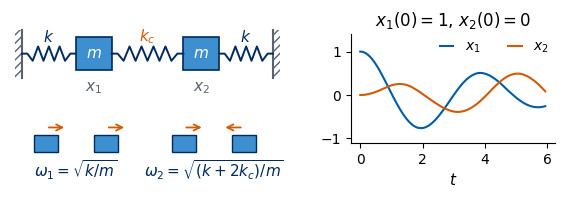

In [29]:
def draw_two_masses(ax, y=0.0):
    """Wall - k - m - k_c - m - k - wall."""
    draw_wall(ax, 0.0, y - 0.4, y + 0.4); draw_wall(ax, 4.2, y - 0.4, y + 0.4, side="right")
    draw_spring(ax, 0.0, 0.9, y, n_coils=4); draw_spring(ax, 1.5, 2.7, y, n_coils=5); draw_spring(ax, 3.3, 4.2, y, n_coils=4)
    for xm, lab in [(0.9, "1"), (2.7, "2")]:
        ax.add_patch(Rectangle((xm, y - 0.28), 0.6, 0.56, facecolor=UJSky, edgecolor=UJNavy, lw=1.2))
        ax.text(xm + 0.3, y, f"$m$", ha="center", va="center", fontsize=11, color="white")
        ax.text(xm + 0.3, y - 0.45, f"$x_{lab}$", ha="center", va="top", fontsize=11, color=UJGray)
    ax.text(0.45, y + 0.2, "$k$", ha="center", fontsize=11, color=UJNavy)
    ax.text(2.1, y + 0.2, "$k_c$", ha="center", fontsize=11, color=DSOrange)
    ax.text(3.75, y + 0.2, "$k$", ha="center", fontsize=11, color=UJNavy)

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.75), layout="none")
    a0 = fig.add_axes([0.0, 0.42, 0.5, 0.55]); draw_two_masses(a0); a0.set_xlim(-0.2, 4.4); a0.set_ylim(-0.75, 0.55)
    a0.set_aspect("equal"); a0.axis("off")
    for j, (title, sgn, om_lab) in enumerate([("in phase", 1, r"$\omega_1=\sqrt{k/m}$"), ("anti-phase", -1, r"$\omega_2=\sqrt{(k+2k_c)/m}$")]):
        a = fig.add_axes([0.0 + 0.25 * j, 0.0, 0.24, 0.36])
        for xm, s in [(0.6, 1), (1.6, sgn)]:
            a.add_patch(Rectangle((xm, -0.2), 0.4, 0.4, facecolor=UJSky, edgecolor=UJNavy, lw=1))
            a.annotate("", xy=(xm + 0.2 + 0.35 * s, 0.38), xytext=(xm + 0.2, 0.38), arrowprops=dict(arrowstyle="->", color=DSOrange, lw=1.3))
        a.text(1.3, -0.35, om_lab, ha="center", va="top", fontsize=11, color=UJNavy)
        a.set_xlim(0.2, 2.4); a.set_ylim(-0.9, 0.6); a.axis("off")
    a1 = fig.add_axes([0.62, 0.22, 0.37, 0.62])
    X_demo = np.asarray(simulate_two(*(jnp.array([v]) for v in (2.0, 0.6, 0.25, 1.0, 0.0, 0.0, 0.0)), jax.random.key(3)))[0]
    a1.plot(t_grid, X_demo[0], color=UJBlue, label="$x_1$"); a1.plot(t_grid, X_demo[1], color=DSOrange, label="$x_2$")
    a1.set_xlabel("$t$"); a1.legend(loc="upper right", ncol=2, handlelength=1.0, borderaxespad=0.0)
    a1.set_ylim(-1.1, 1.4); a1.set_title(r"$x_1(0)=1$, $x_2(0)=0$")
    save(fig, "gen_traj_coupled_sketch.png"); plt.show()

### 6.2 Data

The spring constants are drawn uniformly, $k\in[1,4]$ and $k_c\in[0.2,2]$, the friction log-uniformly, $\gamma\in[0.2,2]$, and the initial conditions uniformly, $x_1(0)\in[0.5,1.5]$, $x_2(0)\in[-1,1]$, $\dot x_{1,2}(0)\in[-0.5,0.5]$; $D$, $\Delta t$ and the 100 recorded times are those of Section 2. The input of the network is the two-channel trajectory $\big(x_1(t_i),x_2(t_i)\big)$, flattened to 200 numbers. Because $k$ and $k_c$ are drawn independently, $\omega_1=\sqrt k$ and $\omega_2=\sqrt{k+2k_c}$ are correlated, and $\omega_2$ is correlated with both springs. This is what makes the question decidable: a coordinate that follows $\omega_2$ has $|\rho|$ close to 1 with $\omega_2$ but clearly smaller with $k_c$, and vice versa.

In [30]:
K_RANGE, KC_RANGE, GAMMA2_RANGE = (1.0, 4.0), (0.2, 2.0), (0.2, 2.0)
def make_two_data(n, seed):
    """n trajectories of two coupled masses, (n, 2, 100), and factors (n, 7) = (k, k_c, gamma, x1, x2, v1, v2) at t = 0."""
    rng = np.random.default_rng(seed)
    kk, kc_, ga = rng.uniform(*K_RANGE, n), rng.uniform(*KC_RANGE, n), np.exp(rng.uniform(*np.log(GAMMA2_RANGE), n))
    x1, x2 = rng.uniform(*X0_RANGE, n), rng.uniform(-1.0, 1.0, n)
    v1, v2 = rng.uniform(-V0_MAX, V0_MAX, n), rng.uniform(-V0_MAX, V0_MAX, n)
    X = simulate_two(*(jnp.asarray(a, jnp.float32) for a in (kk, kc_, ga, x1, x2, v1, v2)), jax.random.key(seed))
    return np.asarray(X, np.float32), np.stack([kk, kc_, ga, x1, x2, v1, v2], 1)

X2tr, F2tr = make_two_data(20_000, seed=11)
X2te, F2te = make_two_data(5_000, seed=12)
w1_te, w2_te = np.sqrt(F2te[:, 0]), np.sqrt(F2te[:, 0] + 2 * F2te[:, 1])
P2_springs = np.stack([F2te[:, 0], F2te[:, 1], np.log(F2te[:, 2])], 1)
P2_modes = np.stack([w1_te, w2_te, np.log(F2te[:, 2])], 1)
P2_ic = F2te[:, 3:]
print("correlations in the test data:  rho(omega_2, k) = %.2f,  rho(omega_2, k_c) = %.2f,  rho(omega_1, omega_2) = %.2f"
      % (np.corrcoef(w2_te, F2te[:, 0])[0, 1], np.corrcoef(w2_te, F2te[:, 1])[0, 1], np.corrcoef(w1_te, w2_te)[0, 1]))
nums["two_data_corr"] = {"w2_k": float(np.corrcoef(w2_te, F2te[:, 0])[0, 1]), "w2_kc": float(np.corrcoef(w2_te, F2te[:, 1])[0, 1]),
                         "w1_w2": float(np.corrcoef(w1_te, w2_te)[0, 1])}

correlations in the test data:  rho(omega_2, k) = 0.63,  rho(omega_2, k_c) = 0.75,  rho(omega_1, omega_2) = 0.63


In the test data $\rho(\omega_2,k)=0.63$, $\rho(\omega_2,k_c)=0.75$ and $\rho(\omega_1,\omega_2)=0.63$. A coordinate that follows $\omega_2$ perfectly would therefore have $|\rho|=0.75$ with $k_c$, and one that follows $k_c$ perfectly $|\rho|=0.75$ with $\omega_2$.

### 6.3 Springs or normal modes

We train the same $\beta$-VAE with 200 inputs and $d=10$ latent coordinates, for $\beta=4$ and two seeds, and correlate the active coordinates with two descriptions of the same oscillator: the spring constants $(k,k_c,\ln\gamma)$ and the normal-mode frequencies $(\omega_1,\omega_2,\ln\gamma)$. The cell prints, for every model, the largest $|\rho|$ of each parameter over the active coordinates.

In [31]:
D2_LATENT, BETAS2, SEEDS2 = 10, [4], [0, 1]
t0 = time.time()
vaes2, ev2 = {}, {}
X2tr_flat, X2te_flat = X2tr.reshape(len(X2tr), -1), X2te.reshape(len(X2te), -1)     # (n, 200): x1(t) then x2(t)
for beta in BETAS2:
    for seed in SEEDS2:
        vaes2[beta, seed], _ = train(lambda s: TrajVAE(2 * T_POINTS, D2_LATENT, rngs=nnx.Rngs(s)), partial(beta_vae_loss, beta=beta),
                                     (X2tr_flat,), EPOCHS, seed, name=f"lab028_two_beta{beta}_seed{seed}")
        ev2[beta, seed] = evaluate(vaes2[beta, seed], X2te_flat)
print(f"{len(vaes2)} models ready in {time.time() - t0:.0f} s")
summary2 = {}
for key in vaes2:
    mu, lv = ev2[key][0], ev2[key][1]
    kl2 = np.asarray(kl_per_dim(mu, lv)).mean(0); act2 = np.flatnonzero(kl2 > ACTIVE_NATS)
    act2 = act2[np.argsort(kl2[act2])[::-1]]
    c_spr, c_mod, c_ic = abs_corr(mu, P2_springs)[act2], abs_corr(mu, P2_modes)[act2], abs_corr(mu, P2_ic)[act2]
    summary2[key] = dict(active=act2, kl=kl2, c_spr=c_spr, c_mod=c_mod, c_ic=c_ic)
    print(f"beta {key[0]}, seed {key[1]}: rate {ev2[key][2]:.2f}, distortion {ev2[key][3]:.2f}, active {len(act2)};"
          f"  best |rho| with k, k_c, ln gamma: {np.round(c_spr.max(0), 2)};  with omega_1, omega_2, ln gamma: {np.round(c_mod.max(0), 2)}")
nums["two"] = {f"{b}_{s}": {"n_active": int(len(v["active"])), "best_springs": v["c_spr"].max(0).round(3).tolist(),
                            "best_modes": v["c_mod"].max(0).round(3).tolist()} for (b, s), v in summary2.items()}

2 models ready in 24 s
beta 4, seed 0: rate 10.45, distortion 20.31, active 7;  best |rho| with k, k_c, ln gamma: [0.73 0.5  0.51];  with omega_1, omega_2, ln gamma: [0.74 0.59 0.51]
beta 4, seed 1: rate 10.63, distortion 19.29, active 7;  best |rho| with k, k_c, ln gamma: [0.68 0.65 0.48];  with omega_1, omega_2, ln gamma: [0.69 0.63 0.48]


model shown: beta = 4, seed = 1
rows: active coordinates; columns: k, k_c, ln gamma | omega_1, omega_2, ln gamma | x1(0), x2(0), v1(0), v2(0)
[[0.68 0.18 0.47 0.69 0.6  0.47 0.06 0.17 0.17 0.11]
 [0.16 0.07 0.08 0.17 0.03 0.08 0.1  0.89 0.05 0.  ]
 [0.26 0.12 0.48 0.24 0.05 0.48 0.46 0.32 0.12 0.2 ]
 [0.22 0.65 0.22 0.21 0.63 0.22 0.02 0.12 0.06 0.28]
 [0.32 0.12 0.47 0.32 0.12 0.47 0.73 0.01 0.18 0.14]
 [0.17 0.26 0.11 0.17 0.09 0.11 0.16 0.02 0.31 0.56]
 [0.08 0.09 0.09 0.09 0.13 0.09 0.15 0.09 0.71 0.3 ]]


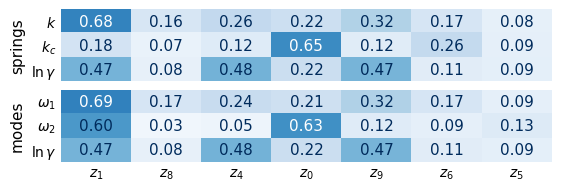

In [32]:
key2 = max(vaes2, key=lambda kk: summary2[kk]["c_mod"].max(0)[:2].sum() + summary2[kk]["c_spr"].max(0)[:2].sum())
s2 = summary2[key2]
print(f"model shown: beta = {key2[0]}, seed = {key2[1]}")
print("rows: active coordinates; columns: k, k_c, ln gamma | omega_1, omega_2, ln gamma | x1(0), x2(0), v1(0), v2(0)")
print(np.round(np.c_[s2["c_spr"], s2["c_mod"], s2["c_ic"]], 2))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 1.8), sharex=True)
    for a, Cm, labels in [(axs[0], s2["c_spr"].T, ["$k$", "$k_c$", r"$\ln\gamma$"]),
                          (axs[1], s2["c_mod"].T, [r"$\omega_1$", r"$\omega_2$", r"$\ln\gamma$"])]:
        a.imshow(Cm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for (r, c), v in np.ndenumerate(Cm):
            a.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=11, color="white" if v > 0.6 else UJNavy)
        a.set_yticks(range(3)); a.set_yticklabels(labels)
        a.spines[:].set_visible(False); a.tick_params(length=0)
    axs[0].set_ylabel("springs"); axs[1].set_ylabel("modes")
    axs[1].set_xticks(range(len(s2["active"]))); axs[1].set_xticklabels([f"$z_{{{k}}}$" for k in s2["active"]])
    save(fig, "gen_traj_coupled_corr.png"); plt.show()
nums["two_show"] = {"beta": key2[0], "seed": key2[1], "c_spr": np.round(s2["c_spr"], 3).tolist(), "c_mod": np.round(s2["c_mod"], 3).tolist()}

Both seeds have seven active coordinates, one per factor ($k$, $k_c$, $\gamma$ and four initial values). The figure shows seed 1. Coordinate $z_1$ follows $k$ ($|\rho|=0.68$) and $\omega_1=\sqrt k$ (0.69), the same statement, since $\omega_1$ is a monotonic function of $k$; it also correlates with $\omega_2$ (0.60) and $\ln\gamma$ (0.47). Coordinate $z_0$ follows $k_c$ with $0.65$ and $\omega_2$ with $0.63$. This difference is far too small to decide the question of Section 6.2: a pure $\omega_2$ coordinate would correlate with $k_c$ at only 0.75, and a pure $k_c$ coordinate with $\omega_2$ at 0.75, while $z_0$ reaches neither value with either parameter, so it is a mixture. In seed 0 the corresponding coordinate prefers $\omega_2$ slightly (0.59 against 0.50 with $k_c$). The friction is not isolated: three coordinates correlate with $\ln\gamma$ at 0.47–0.48, each together with an initial condition. The initial conditions themselves take four coordinates: $x_2(0)$ with 0.89, $x_1(0)$ with 0.73, $\dot x_1(0)$ with 0.71 and $\dot x_2(0)$ with 0.56.

The answer is therefore negative on both sides: the $\beta$-VAE does not find the normal-mode frequencies as such, and it does not find the springs either. One coordinate tracks the in-phase frequency, a second one the coupling, in a mixture of the two descriptions. With seven factors and two channels the problem is harder than for one oscillator, and, as there, the most visible factors, here the initial positions, are captured most cleanly.

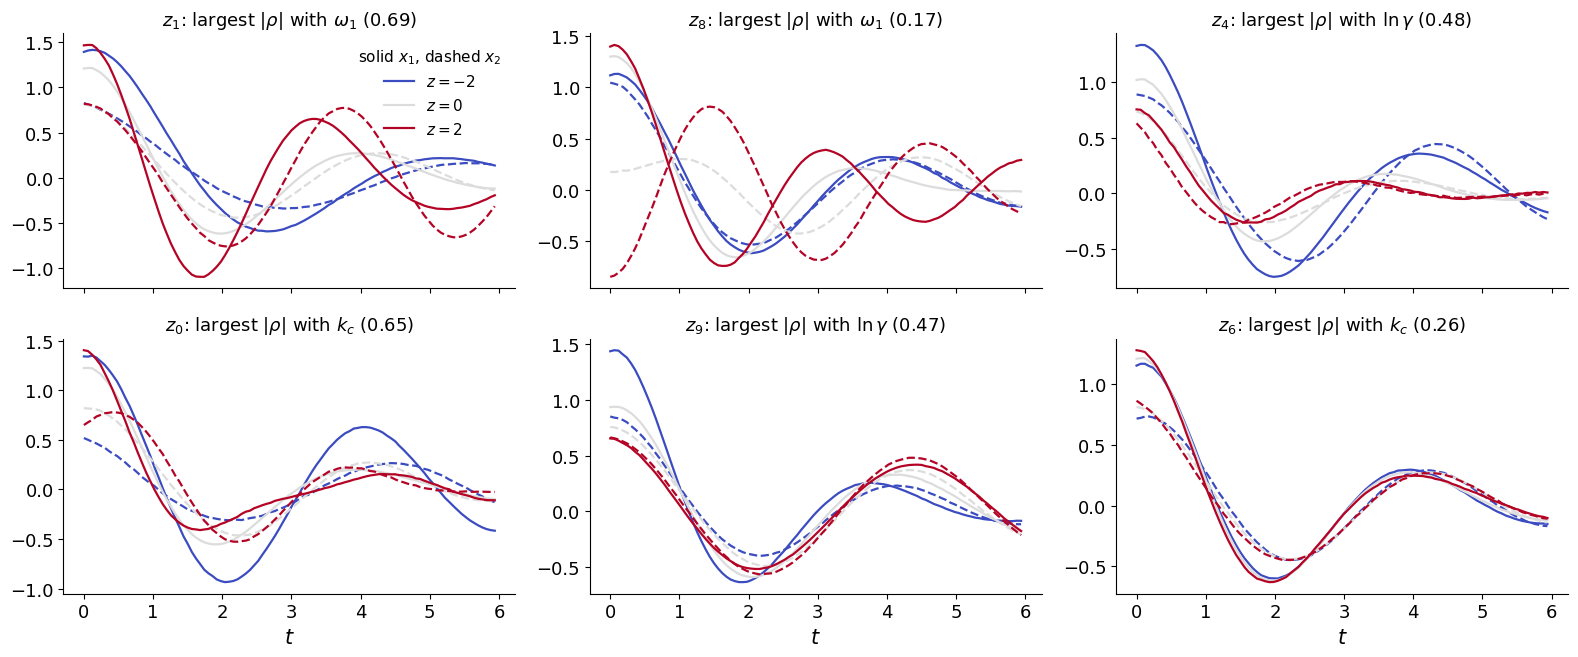

In [33]:
ref2 = int(np.argmin(np.abs(F2te[:, 0] - 2.5) + np.abs(F2te[:, 1] - 1.0) + np.abs(F2te[:, 2] - 0.5)))
mu_ref2 = ev2[key2][0][ref2]
coords2 = list(s2["active"][:6])
fig, axs = plt.subplots(int(np.ceil(len(coords2) / 3)), 3, figsize=(16, 3.4 * np.ceil(len(coords2) / 3)), squeeze=False, sharex=True)
for a, kz in zip(axs.ravel(), coords2):
    for v in [-2, 0, 2]:
        Z = mu_ref2.copy(); Z[kz] = v
        cv = np.asarray(decode(vaes2[key2], jnp.asarray(Z[None], jnp.float32)))[0].reshape(2, T_POINTS)
        col = plt.cm.coolwarm((v + 2) / 4)
        a.plot(t_grid, cv[0], color=col, lw=1.6, label=f"$z={v}$")
        a.plot(t_grid, cv[1], color=col, lw=1.6, ls="--")
    r = list(s2["active"]).index(kz)
    best = [("k", s2["c_spr"][r, 0]), ("k_c", s2["c_spr"][r, 1]), (r"\omega_1", s2["c_mod"][r, 0]),
            (r"\omega_2", s2["c_mod"][r, 1]), (r"\ln\gamma", s2["c_mod"][r, 2])]
    nm, vv = max(best, key=lambda p: p[1])
    a.set_title(rf"$z_{{{kz}}}$: largest $|\rho|$ with ${nm}$ ({vv:.2f})", fontsize=13)
for a in axs.ravel()[len(coords2):]: a.axis("off")
axs[0, 0].legend(fontsize=11, title="solid $x_1$, dashed $x_2$", title_fontsize=11)
for a in axs[-1]: a.set_xlabel("$t$")
plt.tight_layout(); plt.show()

The traversals show the two spring-related coordinates at work. Moving $z_1$ changes the frequency of the motion of both masses together: at $z=2$ (red) both oscillate faster than at $z=-2$ (blue), the in-phase frequency $\omega_1$. Moving $z_0$ changes mainly the relative motion of the two masses, how far $x_1$ (solid) and $x_2$ (dashed) separate after the start, i.e. the anti-phase content and its frequency. $z_8$ sets the initial position of the second mass, and $z_4$ and $z_9$ change the damping together with the starting values.

<hr/>
## Summary

The Langevin equation of a damped oscillator with white noise was integrated with the Euler–Maruyama scheme, whose noise step scales as $\sqrt{\Delta t}$; its mean and stationary variance agree with the exact results $e^{At}\mathbf s(0)$ and $\langle x^2\rangle=D/(\gamma\omega^2)$ up to an error of order $\Delta t$ (about 5% at $\Delta t=0.01$ for the variance).

A $\beta$-VAE with a Gaussian decoder, whose reconstruction term is a scaled mean squared error, trained on 20 000 noisy trajectories without labels, uses four latent coordinates for four factors at $\beta=1$ and in two of the three seeds at $\beta=4$ (the third has a fifth, weak coordinate of 0.13 nats); at $\beta=8$ it drops the initial velocity, the least visible factor. The damping is the one physical parameter that ends up in a coordinate of its own ($|\rho|=0.87$ with $\ln\gamma$); in the overdamped regime this coordinate follows $\omega^2/\gamma$, the slow decay rate, which is the combination the data actually contain. The frequency is stored together with the initial position, because the encoder can measure a frequency only as precisely as the oscillation is visible. The mutual information gap stays between 0.03 and 0.07 for all $\beta$ and seeds, against 0.92 for the true factors. The Fisher information of the trajectories explains the ranking: the visibility of a parameter decides whether it is stored, the overlap of the sensitivity directions and the nonlinearity of the map decide whether it is stored alone.

The question-and-answer network SciNet of Iten *et al.* reproduces their result when trained as long as in the paper (one neuron for $\kappa$, one for $b$, $|\rho|=1.00$ and $0.98$), and the $\beta$-VAE finds the same two parameters with a much stronger KL term in a fraction of the training. Noise of the size used here changes little; nuisance initial conditions change which parameters are stored first. For two coupled masses the $\beta$-VAE finds one coordinate for the in-phase frequency and one that mixes the coupling constant with the anti-phase frequency: it decides neither for the springs nor for the normal modes.

The general lesson: a latent coordinate becomes interpretable when its parameter is visible in the data, when no other parameter changes the data in a similar way, and when the training is long enough; and a coordinate has to be checked against known physics before it is given a name.

<hr/>
## Exercises

### Exercise 1 — Euler–Maruyama for a free Brownian particle
A free overdamped Brownian particle obeys $\dot x=\sqrt{2D}\,\xi(t)$. (a) Write the Euler–Maruyama update and show that, for $x_0=0$, $\langle x_n^2\rangle=2Dn\Delta t$ for **every** step size $\Delta t$. (b) Explain why the noise term must scale as $\sqrt{\Delta t}$: what happens to $\langle x^2\rangle$ at a fixed time if it scaled as $\Delta t$? (c) Check (a) numerically for two step sizes.

#### Solution
(a) $x_{n+1}=x_n+\sqrt{2D\Delta t}\,\eta_n$, hence $x_n=\sqrt{2D\Delta t}\sum_{j<n}\eta_j$ and, since the $\eta_j$ are independent with unit variance, $\langle x_n^2\rangle=2D\Delta t\,n=2Dt_n$. The scheme is exact for this equation, at any $\Delta t$. (b) With a term $\propto\Delta t\,\eta_n$ one would get $\langle x_n^2\rangle\propto n\Delta t^2=t_n\Delta t\to0$ for $\Delta t\to0$: the particle would stop diffusing in the continuum limit. Only $\sqrt{\Delta t}$ gives a limit that does not depend on the step size. (c):

In [34]:
# free Brownian particle: x_{n+1} = x_n + sqrt(2 D dt) eta_n,  x_0 = 0  ->  <x_n^2> = 2 D n dt for every dt
D_ex, n_walk = 0.5, 200_000
for dt_ex in [0.5, 0.05]:
    steps = int(2.0 / dt_ex)
    x = np.zeros(n_walk)
    rng = np.random.default_rng(0)
    for _ in range(steps):
        x += np.sqrt(2 * D_ex * dt_ex) * rng.standard_normal(n_walk)
    print(f"dt = {dt_ex}: <x^2>(t = 2) = {np.mean(x**2):.4f},  exact 2 D t = {2 * D_ex * 2.0:.4f}")

dt = 0.5: <x^2>(t = 2) = 1.9908,  exact 2 D t = 2.0000


dt = 0.05: <x^2>(t = 2) = 1.9986,  exact 2 D t = 2.0000


Both step sizes reproduce $2Dt=2$ within the sampling error, about 0.3% for 200 000 walkers: 1.9908 for $\Delta t=0.5$ and 1.9986 for $\Delta t=0.05$.

### Exercise 2 — Stationary variance of the Ornstein–Uhlenbeck process
In the overdamped limit the oscillator obeys $\gamma\dot x=-\omega^2x+\sqrt{2D}\,\xi(t)$. (a) Check that $x(t)=\int_0^te^{-r(t-s)}\frac{\sqrt{2D}}{\gamma}\xi(s)\,ds$ with $r=\omega^2/\gamma$ solves it for $x(0)=0$. (b) Using $\langle\xi(s)\xi(s')\rangle=\delta(s-s')$, compute $\langle x(t)^2\rangle$ and its limit $t\to\infty$. Compare with the underdamped result of Section 1.3.

#### Solution
(a) Differentiating, $\dot x=\frac{\sqrt{2D}}{\gamma}\xi(t)-r\,x(t)$, which is the equation divided by $\gamma$. (b) $\langle x^2\rangle=\frac{2D}{\gamma^2}\int_0^t\!\int_0^te^{-r(t-s)}e^{-r(t-s')}\delta(s-s')\,ds\,ds'=\frac{2D}{\gamma^2}\int_0^te^{-2r(t-s)}ds$; SymPy evaluates the integral:

In [35]:
s_, tau, D_, g_, w_s = sp.symbols("s tau D gamma omega", positive=True)
r_ = w_s**2 / g_                                                  # relaxation rate of the overdamped particle
# x(t) = int_0^t e^{-r (t - s)} (sqrt(2D)/gamma) xi(s) ds  ->  <x^2> = (2D/gamma^2) int_0^t e^{-2 r (t - s)} ds
var_t = (2 * D_ / g_**2) * sp.integrate(sp.exp(-2 * r_ * (tau - s_)), (s_, 0, tau))
print("<x^2>(t) =", sp.simplify(var_t))
print("t -> infinity:", sp.limit(var_t, tau, sp.oo))

<x^2>(t) = D/(gamma*omega**2) - D*exp(-2*omega**2*tau/gamma)/(gamma*omega**2)
t -> infinity: D/(gamma*omega**2)


The limit is $D/(\gamma\omega^2)$, the same as $\langle x^2\rangle$ of the full oscillator in Section 1.3. The stationary distribution of the position does not depend on the mass, as it must for a Boltzmann distribution $\propto e^{-\omega^2x^2/(2k_BT)}$ with $k_BT=D/\gamma$ (units with $m=1$).

### Exercise 3 — A stronger random force
Generate the data of Section 2 with $D$ ten times larger and train a $\beta$-VAE with $\beta=4$ (60 epochs suffice for a first look). How do the rate, the distortion, the number of active coordinates and the best correlations with the four factors change? Relate the answer to the noise-floor argument of Section 3.3.

#### Solution

In [36]:
# a ten times larger noise strength
Xtr_D, _ = make_oscillator_data(20_000, seed=31, D=10 * D_NOISE)
Xte_D, Fte_D = make_oscillator_data(5_000, seed=32, D=10 * D_NOISE)
vae_D, _ = train(lambda s: TrajVAE(T_POINTS, D_LATENT, rngs=nnx.Rngs(s)), partial(beta_vae_loss, beta=4), (Xtr_D,), 60, 0,
                 name="lab028_ex_D10_beta4")
mu_D, lv_D, R_D, Drec_D = evaluate(vae_D, Xte_D)
act_D = np.flatnonzero(np.asarray(kl_per_dim(mu_D, lv_D)).mean(0) > ACTIVE_NATS)
print(f"D = {10 * D_NOISE}: rate {R_D:.2f} nats, distortion {Drec_D:.2f}, active coordinates {len(act_D)}")
print("best |rho| over active coordinates (omega, ln gamma, x0, v0):", np.round(abs_corr(mu_D, probe_factors(Fte_D))[act_D].max(0), 2))
print("for comparison, D = %.3f, beta = 4 (mean over seeds):" % D_NOISE, np.round(np.mean([best_corr[4, s] for s in SEEDS], 0), 2))

D = 0.02: rate 6.74 nats, distortion 13.96, active coordinates 5
best |rho| over active coordinates (omega, ln gamma, x0, v0): [0.44 0.76 0.67 0.43]
for comparison, D = 0.002, beta = 4 (mean over seeds): [0.55 0.82 0.6  0.56]


With $D=0.02$ the model has five active coordinates instead of four, a rate of 6.74 nats and a distortion of 13.96 nats. The best correlations with $\omega$, $\ln\gamma$ and $v_0$ drop, from 0.55, 0.82 and 0.56 (mean over the seeds at $D=0.002$) to 0.44, 0.76 and 0.43, while the one with $x_0$ rises from 0.60 to 0.67. Ten times more noise raises the noise floor tenfold; the trajectories deviate from their means by about three times more, the small details by which $\omega$ and $v_0$ are recognised are drowned first, and the code spends a coordinate on the noise. The damping and the initial position, the most visible factors, survive best. (A single seed with 60 epochs; for firm conclusions, repeat with several seeds.)

### Exercise 4 — A driving frequency as a third parameter
Add a periodic force $F\cos(\Omega t)$ with $F=0.5$ to the equation of motion and draw $\Omega$ uniformly in $[0.5,2.5]$ for every trajectory. Train a $\beta$-VAE with $\beta=4$ and correlate its active coordinates with $(\omega,\ln\gamma,\Omega,x_0,v_0)$. Does a coordinate follow the driving frequency? Which of the five factors is easiest to find, and why?

#### Solution

In [37]:
# a third physical parameter: the frequency Omega of a driving force F cos(Omega t), F = 0.5
F_DRIVE = 0.5
def simulate_driven(omega, gamma, Omega, x0, v0, key, D=D_NOISE, dt=DT, n_sub=N_SUB, n_rec=T_POINTS):
    def em_step(state, inp):
        (x, v), (k, tn) = state, inp
        eta = jax.random.normal(k, x.shape)
        return (x + v * dt, v + (-omega**2 * x - gamma * v + F_DRIVE * jnp.cos(Omega * tn)) * dt + jnp.sqrt(2 * D * dt) * eta), None
    def record(state, inp):
        k, n0 = inp
        state, _ = jax.lax.scan(em_step, state, (jax.random.split(k, n_sub), (n0 + jnp.arange(n_sub)) * dt))
        return state, state[0]
    _, xs = jax.lax.scan(record, (x0, v0), (jax.random.split(key, n_rec - 1), n_sub * jnp.arange(n_rec - 1)))
    return jnp.concatenate([x0[None], xs]).T

def make_driven(n, seed):
    rng = np.random.default_rng(seed)
    om, ga = rng.uniform(*OMEGA_RANGE, n), np.exp(rng.uniform(*np.log(GAMMA_RANGE), n))
    Om, x0, v0 = rng.uniform(0.5, 2.5, n), rng.uniform(*X0_RANGE, n), rng.uniform(-V0_MAX, V0_MAX, n)
    X = simulate_driven(*(jnp.asarray(a, jnp.float32) for a in (om, ga, Om, x0, v0)), jax.random.key(seed))
    return np.asarray(X, np.float32), np.stack([om, np.log(ga), Om, x0, v0], 1)

Xtr_dr, _ = make_driven(20_000, 41)
Xte_dr, Pte_dr = make_driven(5_000, 42)
vae_dr, _ = train(lambda s: TrajVAE(T_POINTS, D_LATENT, rngs=nnx.Rngs(s)), partial(beta_vae_loss, beta=4), (Xtr_dr,), 60, 0,
                  name="lab028_ex_driven_beta4")
mu_dr, lv_dr, _, _ = evaluate(vae_dr, Xte_dr)
kl_dr = np.asarray(kl_per_dim(mu_dr, lv_dr)).mean(0); act_dr = np.flatnonzero(kl_dr > ACTIVE_NATS)
print("active coordinates:", len(act_dr))
print("|rho| (rows: active coordinates; columns: omega, ln gamma, Omega, x0, v0)")
print(np.round(abs_corr(mu_dr, Pte_dr)[act_dr], 2))

active coordinates: 6
|rho| (rows: active coordinates; columns: omega, ln gamma, Omega, x0, v0)
[[0.12 0.02 0.26 0.2  0.3 ]
 [0.21 0.58 0.1  0.18 0.12]
 [0.13 0.04 0.04 0.65 0.17]
 [0.57 0.55 0.25 0.13 0.16]
 [0.3  0.13 0.27 0.33 0.3 ]
 [0.2  0.35 0.5  0.16 0.15]]


The driven model has six active coordinates. The driving frequency is found only partially: its best coordinate reaches $|\rho|=0.50$ with $\Omega$ and also 0.35 with $\ln\gamma$. The initial position is again the cleanest factor of this model (0.65 in one coordinate), the damping reaches 0.58, and $\omega$ is shared with $\ln\gamma$ (0.57 and 0.55 in the same coordinate). With $F=0.5$ the driving force adds a response of amplitude $F/\sqrt{(\omega^2-\Omega^2)^2+\gamma^2\Omega^2}$ that depends on all three of $\omega$, $\gamma$ and $\Omega$, and within six time units the driven oscillation is still mixed with the transient: $\Omega$ is only moderately visible and is confused with the other two frequencies.

### Exercise 5 (open) — Hopping in a double well
Replace the spring by the double-well potential $V(x)=a(x^2-1)^2$, i.e. $\ddot x=-V'(x)-\gamma\dot x+\sqrt{2D}\,\xi$, and vary the barrier height $a$ and the temperature $k_BT=D/\gamma$ between trajectories, with a time window long enough to see several jumps between the wells. The mean time between jumps follows Kramers' law, $\tau\propto e^{a/k_BT}$ [Kramers 1940; Hänggi, Talkner and Borkovec 1990]. Train a $\beta$-VAE on the trajectories and test whether a latent coordinate follows $\ln\tau$, i.e. $a/k_BT$, rather than $a$ or $T$ separately. Hint: the time of the first jump is random and differs between trajectories with the same parameters, so the encoder must summarise statistics of the trajectory, not its shape; a summary input such as the histogram of $x$ or the sequence of well occupations may work better than the raw positions.

### Exercise 6 (open) — Long training with noise and nuisance factors
Section 5.4 trains SciNet for 1000 epochs only in the noise-free setting of the paper. Train it for 1000 epochs also on the data with noise and on the data with noise and random initial conditions (five latent neurons). Does it then store $\kappa$, $b$, $x_0$ and $v_0$ in separate neurons? Compare with the $\beta$-VAE, and explain the result through the cost: which parameters improve the answers to the questions $t\in[0,10]$ the most?

<hr/>
## References

* R. Iten, T. Metger, H. Wilming, L. del Rio, R. Renner, *Discovering Physical Concepts with Neural Networks*, Phys. Rev. Lett. **124**, 010508 (2020), [doi:10.1103/PhysRevLett.124.010508](https://link.aps.org/doi/10.1103/PhysRevLett.124.010508); open-access version with the Supplemental Material: [arXiv:1807.10300](https://arxiv.org/abs/1807.10300)
* I. Higgins, L. Matthey, A. Pal, C. Burgess, X. Glorot, M. Botvinick, S. Mohamed, A. Lerchner, *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework*, ICLR 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl)
* R. T. Q. Chen, X. Li, R. Grosse, D. Duvenaud, *Isolating Sources of Disentanglement in Variational Autoencoders*, NeurIPS 2018, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942) (mutual information gap)
* F. Locatello, S. Bauer, M. Lucic, G. Rätsch, S. Gelly, B. Schölkopf, O. Bachem, *Challenging Common Assumptions in the Unsupervised Learning of Disentangled Representations*, ICML 2019, [PMLR 97, 4114](https://proceedings.mlr.press/v97/locatello19a.html)
* P. E. Kloeden, E. Platen, *Numerical Solution of Stochastic Differential Equations*, Springer (1992), [doi:10.1007/978-3-662-12616-5](https://doi.org/10.1007/978-3-662-12616-5)
* D. J. Higham, *An Algorithmic Introduction to Numerical Simulation of Stochastic Differential Equations*, SIAM Rev. **43**, 525 (2001), [doi:10.1137/S0036144500378302](https://doi.org/10.1137/S0036144500378302)
* G. E. Uhlenbeck, L. S. Ornstein, *On the Theory of the Brownian Motion*, Phys. Rev. **36**, 823 (1930), [doi:10.1103/PhysRev.36.823](https://doi.org/10.1103/PhysRev.36.823)
* S. Chandrasekhar, *Stochastic Problems in Physics and Astronomy*, Rev. Mod. Phys. **15**, 1 (1943), [doi:10.1103/RevModPhys.15.1](https://doi.org/10.1103/RevModPhys.15.1)
* H. A. Kramers, *Brownian motion in a field of force and the diffusion model of chemical reactions*, Physica **7**, 284 (1940), [doi:10.1016/S0031-8914(40)90098-2](https://doi.org/10.1016/S0031-8914(40)90098-2)
* P. Hänggi, P. Talkner, M. Borkovec, *Reaction-rate theory: fifty years after Kramers*, Rev. Mod. Phys. **62**, 251 (1990), [doi:10.1103/RevModPhys.62.251](https://doi.org/10.1103/RevModPhys.62.251)

In [38]:
nums["runtime_s"] = round(time.time() - t_start, 1)
with open(f"{OUT}/numbers_lab028.json", "w") as fh:
    json.dump(nums, fh, indent=1)
sh = nums["show"]; ccol = lambda j: [r[j] for r in sh["corr"]]
qa = nums["qa"]
macros = {
    "trNtrain": f"{nums['data']['n_train']:,}".replace(",", "\\,"), "trOver": f"{100 * nums['data']['overdamped_frac']:.0f}",
    "trNoise": f"{nums['data']['noise_rms']:.3f}", "trXstd": f"{nums['data']['x_std']:.2f}",
    "trVarExact": f"{nums['em_var_x']['exact']:.5f}", "trVarEM": f"{nums['em_var_x']['em_recursion']:.5f}",
    "trVarEns": f"{nums['em_var_x']['ensemble']:.5f}",
    "trShowSeed": f"{sh['seed']}", "trNact": f"{len(sh['active'])}",
    "trRhoGamma": f"{max(ccol(1)):.2f}", "trRhoOmega": f"{max(ccol(0)):.2f}", "trRhoXzero": f"{max(ccol(2)):.2f}",
    "trRhoVzero": f"{max(ccol(3)):.2f}",
    **{f"trAct{str(b).replace('.', 'p')}": ", ".join(str(v) for v in nums["n_active"][str(b)]) for b in BETAS},
    **{f"trMig{str(b).replace('.', 'p')}": f"{np.mean(nums['mig'][str(b)]):.3f}" for b in BETAS},
    "trMigTrue": f"{nums['mig_true']:.2f}", "trMigRot": f"{nums['mig_rot']:.2f}",
    "trRtwoW": f"{nums['fits_w']['omega']:.2f}", "trRtwoWX": f"{nums['fits_w']['omega, x0, omega*x0']:.2f}",
    "trCosWX": f"{nums['fisher_cos'][0][2]:.2f}", "trCosWG": f"{nums['fisher_cos'][0][1]:.2f}", "trCosGX": f"{nums['fisher_cos'][1][2]:.2f}",
    "trVis": ", ".join(f"{v:.0f}" for v in nums["visibility"]),
    **{f"trQA{i}{n[0]}{q}": f"{qa[f'{i}_{n}']['best'][j]:.2f}" for i in range(3) for n in ("SciNet", "beta-VAE") for j, q in enumerate("kb")},
    **{f"trQA{i}{n[0]}{q}sec": f"{qa[f'{i}_{n}']['second'][j]:.2f}" for i in range(3) for n in ("SciNet", "beta-VAE") for j, q in enumerate("kb")},
    "trQArmse": f"{nums['qa_rmse'][0]:.3f}", "trQArmseLong": f"{nums['qa_rmse_long']:.3f}",
    **{f"trQAlong{q}": f"{nums['qa_long']['best'][j]:.2f}" for j, q in enumerate("kb")},
    **{f"trQAlong{q}sec": f"{nums['qa_long']['second'][j]:.2f}" for j, q in enumerate("kb")},
    "trTwoBeta": f"{nums['two_show']['beta']}", "trTwoSeed": f"{nums['two_show']['seed']}",
    **{f"trTwo{nm}": f"{max(r[j] for r in nums['two_show'][src]):.2f}"
       for nm, src, j in [("K", "c_spr", 0), ("Kc", "c_spr", 1), ("G", "c_spr", 2), ("Wone", "c_mod", 0), ("Wtwo", "c_mod", 1)]},
    "trTwoWtwoKc": f"{nums['two_data_corr']['w2_kc']:.2f}", "trTwoWtwoK": f"{nums['two_data_corr']['w2_k']:.2f}",
    "trUnderG": f"{nums['regimes']['under']['rho_g']:.2f}", "trOverG": f"{nums['regimes']['over']['rho_g']:.2f}",
    "trOverSlow": f"{nums['regimes']['over']['rho_g_slow']:.2f}", "trCosWV": f"{nums['fisher_cos'][0][3]:.2f}",
}
with open("../beamer/sections/nb_numbers_lab028.tex", "w") as fh:
    for k_, v_ in macros.items():
        fh.write(f"\\setnbnum{{{k_}}}{{{v_}}}\n")
print("numbers written")

numbers written
